# Learning Safe Closed-Loop Driving Policies with PPO in the Waymax Simulator

CSCE 642 Deep Reinforcement Learning, course project
Debmalya Chatterjee and Arvinder Singh Mundra

This notebook is the whole project in one place: data loading and analysis, the
Waymax environment wrapper, the reward, PPO, the reference controllers, every
experiment from the proposal, the statistics and the failure analysis. It runs
top to bottom on Google Colab (GPU) or on a local machine.

**Question.** Can a PPO policy with continuous steering and acceleration make progress
along its route in real WOMD scenes without crashing or leaving the road, and how does
it compare with a simple hand-designed controller?

- **H1.** On held-out scenarios, PPO has a lower collision and off-road rate than the
  hand-designed controller at similar route progress.
- **H2.** A policy trained against replayed traffic does worse when the other cars are
  switched to Waymax's reactive IDM agents.
- **H3.** Raising the collision and off-road penalties lowers the failure rate but costs
  progress, and if pushed too far the agent learns to stop and wait.

This notebook was made using the Waymo Open Dataset, provided by Waymo LLC under the
Waymo Dataset License Agreement for Non-Commercial Use, available at
waymo.com/open/terms, and your access and use of such work are governed by the terms
and conditions therein.

## 1. Setup

Waymax is installed from GitHub without its version pins. It was written for JAX 0.4,
so two small patches are applied before importing it: the `jax.tree_*` aliases that
JAX 0.6 removed, and a `jnp.cross` that still accepts 2D vectors (Waymax's off-road
check uses it).

In [1]:
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = "/content/drive/MyDrive/csce642/csce642-waymax-ppo"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps",
                    "git+https://github.com/waymo-research/waymax.git@main#egg=waymo-waymax"],
                   check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "dm_env",
                    "immutabledict", "mediapy", "dm-tree", "chex", "tabulate"], check=True)
else:
    PROJECT = os.environ.get("PROJECT_DIR", os.getcwd())
os.makedirs(PROJECT, exist_ok=True)
os.chdir(PROJECT)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
print("working directory:", os.getcwd())

working directory: /Users/arvindermundra/Downloads/csce642-waymax-ppo


In [2]:
import dataclasses
import functools
import glob
import pickle
import time
import warnings
from typing import Any

import jax
import jax.numpy as jnp
import jax.tree_util as jtu
import matplotlib
import numpy as np
import pandas as pd

for _name in ("tree_map", "tree_leaves", "tree_flatten", "tree_unflatten",
              "tree_structure", "tree_transpose"):
    if not hasattr(jax, _name):
        setattr(jax, _name, getattr(jtu, _name))
_orig_cross = jnp.cross


def _cross(a, b, *args, **kwargs):
    a, b = jnp.asarray(a), jnp.asarray(b)
    if a.shape[-1] == 2 and b.shape[-1] == 2:
        return a[..., 0] * b[..., 1] - a[..., 1] * b[..., 0]
    return _orig_cross(a, b, *args, **kwargs)


jnp.cross = _cross

import optax  # noqa: E402
from flax import linen as nn  # noqa: E402
from flax import struct  # noqa: E402
from flax.training.train_state import TrainState  # noqa: E402
from waymax import agents, dataloader, datatypes, dynamics  # noqa: E402
from waymax import config as wcfg  # noqa: E402
from waymax import env as wenv  # noqa: E402
from waymax.metrics import roadgraph as rg_metrics  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
from matplotlib.patches import Polygon  # noqa: E402
from IPython.display import Markdown, display  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("jax", jax.__version__, jax.devices())
print("bicycle model action spec:", dynamics.InvertibleBicycleModel().action_spec())

jax 0.12.1 [CpuDevice(id=0)]
bicycle model action spec: BoundedArray(shape=(2,), dtype=dtype('float32'), name=None, minimum=[-6.  -0.3], maximum=[6.  0.3])


### Configuration

`SMOKE=1` in the environment runs a tiny version of everything (a few scenes and a
few thousand steps) to check the notebook end to end and writes everything under
`smoke/`; leave it unset for the real run.
Every expensive step writes its output to disk and is skipped when the output already
exists, so the notebook can be rerun after a Colab disconnect without losing work.

In [3]:
SMOKE = os.environ.get("SMOKE", "0") == "1"

TRAIN_TFRECORDS = sorted(glob.glob("data/womd/train/*tfrecord*"))
VAL_TFRECORDS = sorted(glob.glob("data/womd/val/*tfrecord*"))
OUT = "smoke" if SMOKE else "."
CACHE_DIR = "data/cache"
RUNS_DIR = os.path.join(OUT, "runs")
RESULTS_DIR = os.path.join(OUT, "results")
FIG_DIR = os.path.join(OUT, "figures")
VIDEO_DIR = os.path.join(OUT, "videos")
for d in (CACHE_DIR, RUNS_DIR, RESULTS_DIR, FIG_DIR, VIDEO_DIR):
    os.makedirs(d, exist_ok=True)

MAX_OBJECTS = 64          # objects kept per scene: the 64 closest to the ego's logged path
RG_POINTS = 3000          # roadgraph points kept: the ones closest to the ego's route
MAX_TL = 16               # traffic-light slots per scene
WAIT_THRESHOLD = 20.0     # m; scenes where the logged ego moves less are "waiting" scenes
TOTAL_STEPS = 2_000_000 if not SMOKE else 8_192
SEEDS = [0, 1, 2] if not SMOKE else [0]
MAX_SCENES = None if not SMOKE else 24
print("train files:", TRAIN_TFRECORDS)
print("val files:", VAL_TFRECORDS)

train files: ['data/womd/train/training_tfexample.tfrecord-00000-of-01000']
val files: ['data/womd/val/validation_tfexample.tfrecord-00000-of-00150']


## 2. Data: the Waymo Open Motion Dataset

We use one training shard (`training_tfexample.tfrecord-00000-of-01000`) and one
validation shard (`validation_tfexample.tfrecord-00000-of-00150`) of WOMD v1.1 in the
`tf_example` format that Waymax reads. Each scene is 9.1 s of real driving at 10 Hz
(91 steps): 1.1 s of history that Waymax replays, then 80 steps (8 s) that we control.
A scene holds up to 128 tracked objects (vehicles, pedestrians, cyclists) with their
boxes, headings and velocities, about 20,000 map points (lane centres, road edges,
crosswalks, stop signs) and the traffic-light states at every step.

What we keep from each scene:

- **All scenes.** The ego (the car the dataset was recorded from) is tracked for all
  91 steps in every scene of both shards. Scenes where the human barely moves
  (logged path under 20 m: red lights, queues, parking) are kept and analysed as
  *waiting* scenes; the rest are *driving* scenes.
- **The 64 objects closest to the ego's logged path.** Waymax's loader keeps the first
  N objects in file order, which silently drops nearby cars when N is small, so we load
  all 128 and select by distance.
- **The 3,000 map points closest to the ego's route**, enough for the off-road check
  around the ego.
- **Traffic lights on the ego's route.** A signal is on the route when the lane it
  controls is one of the lanes the logged ego drove along.

The route the agent follows is the ego's logged path, resampled every metre and
extended 30 m past its end.

In [4]:
INIT_STEP, LAST_STEP = 10, 90
ROUTE_POINTS, ROUTE_SPACING, ROUTE_EXTENSION = 400, 1.0, 30.0
RED_STATES = (1, 4, 7)          # arrow stop, stop, flashing stop
LANE_TYPES = (1, 2, 3)          # freeway, surface street, bike lane centres
ROAD_EDGE_TYPES = (15, 16)      # road edge boundary, median


def scenario_iterator(path):
    import tensorflow as tf
    tf.config.set_visible_devices([], "GPU")
    cfg = dataclasses.replace(wcfg.WOD_1_1_0_VALIDATION, path=path, max_num_objects=128,
                              repeat=1, shuffle_seed=None)
    for state in dataloader.simulator_state_generator(cfg):
        yield jtu.tree_map(np.asarray, jax.device_get(state))


def sdc_index(s):
    return int(np.argmax(np.asarray(s.object_metadata.is_sdc)))


def select_objects(s, k):
    """Keeps the ego and the k-1 objects that come closest to its logged path."""
    lt = s.log_trajectory
    i = sdc_index(s)
    d = np.hypot(lt.x - lt.x[i][None], lt.y - lt.y[i][None])
    d = np.where(lt.valid & lt.valid[i][None], d, np.inf).min(axis=1)
    d = np.where(np.asarray(s.object_metadata.is_valid), d, np.inf)
    d[i] = -1.0
    near30 = int(((d >= 0) & (d < 30)).sum())
    idx = np.sort(np.argsort(d)[:k])
    take = lambda a: np.asarray(a)[idx]
    s = s.replace(log_trajectory=jtu.tree_map(take, s.log_trajectory),
                  sim_trajectory=jtu.tree_map(take, s.sim_trajectory),
                  object_metadata=jtu.tree_map(take, s.object_metadata))
    return s, near30, int(((d >= 0) & (d < 30)).sum() - ((d[idx] >= 0) & (d[idx] < 30)).sum())


def build_route(s):
    """Resamples the logged ego path to 1 m spacing plus a straight extension."""
    i = sdc_index(s)
    lt = s.log_trajectory
    pts = np.stack([lt.x[i], lt.y[i]], -1).astype(np.float64)
    seg = np.hypot(*np.diff(pts, axis=0).T)
    keep = np.concatenate([[True], seg > 0.05])
    pts_k = pts[keep]
    s_k = np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(pts_k, axis=0).T))])
    s_t = np.interp(np.arange(len(pts)), np.flatnonzero(keep), s_k)
    if len(pts_k) >= 2 and s_k[-1] > 1.0:
        d = pts_k[-1] - pts_k[-2]
    else:                                   # ego never moves: extend along its heading
        d = np.array([np.cos(lt.yaw[i, -1]), np.sin(lt.yaw[i, -1])])
    d = d / (np.linalg.norm(d) + 1e-9)
    ext = np.arange(1, int(ROUTE_EXTENSION) + 1, dtype=np.float64)
    pts_e = np.concatenate([pts_k, pts_k[-1] + ext[:, None] * d])
    s_e = np.concatenate([s_k, s_k[-1] + ext])
    grid = np.arange(ROUTE_POINTS) * ROUTE_SPACING
    route = np.stack([np.interp(grid, s_e, pts_e[:, 0]), np.interp(grid, s_e, pts_e[:, 1])], -1)
    heading = np.unwrap(np.arctan2(np.gradient(route[:, 1]), np.gradient(route[:, 0])))
    kappa = np.convolve(np.gradient(heading) / ROUTE_SPACING, np.ones(5) / 5, mode="same")
    yaw = np.unwrap(lt.yaw[i, INIT_STEP:])
    return dict(
        route=route.astype(np.float32), route_valid=grid <= s_e[-1],
        route_kappa=kappa.astype(np.float32),
        s_init=np.float32(s_t[INIT_STEP]), s_end=np.float32(s_t[LAST_STEP]),
        log_len=np.float32(s_t[LAST_STEP] - s_t[INIT_STEP]),
        log_speed=np.hypot(lt.vel_x[i], lt.vel_y[i]).astype(np.float32),
        turn_deg=np.float32(np.degrees(abs(yaw[-1] - yaw[0]))),
    )


def project_np(route, valid, x, y):
    d2 = np.where(valid, (route[:, 0] - x) ** 2 + (route[:, 1] - y) ** 2, np.inf)
    j = int(np.argmin(d2))
    j0 = min(j, len(route) - 2)
    t = route[j0 + 1] - route[j0]
    t = t / (np.linalg.norm(t) + 1e-9)
    rel = np.array([x, y]) - route[j0]
    return j0 * ROUTE_SPACING + float(rel @ t), float(t[0] * rel[1] - t[1] * rel[0])


def route_traffic_lights(s, r):
    """Finds the signals that control the ego's route.

    A signal counts when the lane it controls is one the logged ego drove along, or,
    for an ego that stopped before the line, when its stop point lies within 2 m of the
    route ahead and its lane points the same way as the route.
    """
    rg, tl = s.roadgraph_points, s.log_traffic_light
    lane = np.asarray(rg.valid) & np.isin(np.asarray(rg.types), LANE_TYPES)
    px, py = np.asarray(rg.x)[lane], np.asarray(rg.y)[lane]
    pdx, pdy = np.asarray(rg.dir_x)[lane], np.asarray(rg.dir_y)[lane]
    pid = np.asarray(rg.ids)[lane]
    route, valid = r["route"], r["route_valid"]
    n_valid = int(valid.sum())

    def tangent(j):
        t = route[min(j + 1, n_valid - 1)] - route[max(j - 1, 0)]
        return t / (np.linalg.norm(t) + 1e-9)

    driven = set()
    for j in range(0, int(min(r["s_end"] + 1, n_valid)), 2):
        q, t = route[j], tangent(j)
        near = (np.hypot(px - q[0], py - q[1]) < 1.5) & (pdx * t[0] + pdy * t[1] > 0.8)
        driven.update(pid[near].tolist())
    out_s = np.zeros(MAX_TL, np.float32)
    out_on = np.zeros(MAX_TL, bool)
    out_red = np.zeros((MAX_TL, 91), bool)
    n = 0
    for k in range(tl.x.shape[0]):
        v = np.asarray(tl.valid[k])
        if not v.any() or n >= MAX_TL:
            continue
        t0 = int(np.argmax(v))
        lane_id = int(np.asarray(tl.lane_ids[k])[t0])
        x, y = float(tl.x[k, t0]), float(tl.y[k, t0])
        s_tl, lat = project_np(route, valid, x, y)
        on = lane_id in driven
        if not on and abs(lat) < 2.0 and r["s_init"] - 2 < s_tl < n_valid - 1:
            mine = pid == lane_id
            if mine.any():
                j = np.argmin(np.hypot(px[mine] - x, py[mine] - y))
                t = tangent(int(round(s_tl)))
                on = pdx[mine][j] * t[0] + pdy[mine][j] * t[1] > 0.7
        if not on:
            continue
        out_s[n], out_on[n] = s_tl, True
        out_red[n] = v & np.isin(np.asarray(tl.state[k]), RED_STATES)
        n += 1
    return dict(tl_s=out_s, tl_on=out_on, tl_red=out_red)


def crop_roadgraph(s, route, k):
    rg = s.roadgraph_points
    px, py = np.asarray(rg.x), np.asarray(rg.y)
    ref = route[::5]
    d2 = ((px[:, None] - ref[None, :, 0]) ** 2 + (py[:, None] - ref[None, :, 1]) ** 2).min(1)
    d2 = np.where(np.asarray(rg.valid), d2, np.inf)
    idx = np.sort(np.argsort(d2)[:k])
    return s.replace(roadgraph_points=jtu.tree_map(lambda a: np.asarray(a)[idx], rg))


def build_bank(paths, max_scenes=None):
    states, routes, meta = [], [], []
    for path in paths:
        for n, s in enumerate(scenario_iterator(path)):
            md = s.object_metadata
            i = sdc_index(s)
            if not (bool(md.is_sdc.any()) and bool(s.log_trajectory.valid[i].all())):
                continue
            seen = np.asarray(s.log_trajectory.valid).any(1) & np.asarray(md.is_valid)
            types = np.asarray(md.object_types)
            r = build_route(s)
            r.update(route_traffic_lights(s, r))
            s_sel, near30, dropped30 = select_objects(s, MAX_OBJECTS)
            s_sel = crop_roadgraph(s_sel, r["route"], RG_POINTS)
            states.append(s_sel)
            routes.append(r)
            meta.append(dict(
                scenario=f"{os.path.basename(path)}#{n}",
                objects=int(seen.sum()), vehicles=int((seen & (types == 1)).sum()),
                pedestrians=int((seen & (types == 2)).sum()),
                cyclists=int((seen & (types == 3)).sum()),
                near30=near30, dropped_near30=dropped30,
                traffic_lights=int(np.asarray(s.log_traffic_light.valid).any(1).sum()),
                route_lights=int(r["tl_on"].sum()),
                red_on_route=bool((r["tl_red"] & r["tl_on"][:, None]).any()),
                log_len=float(r["log_len"]), turn_deg=float(r["turn_deg"]),
                mean_speed=float(r["log_speed"][INIT_STEP:].mean()),
                max_speed=float(r["log_speed"].max())))
            if max_scenes and len(states) >= max_scenes:
                break
        if max_scenes and len(states) >= max_scenes:
            break
    stacked = jtu.tree_map(lambda *a: np.stack(a), *states)
    route_arrays = {k: np.stack([r[k] for r in routes]) for k in routes[0]}
    return dict(states=stacked, routes=route_arrays, meta=pd.DataFrame(meta))


def load_or_build(name, paths):
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    t0 = time.time()
    bank = build_bank(paths, MAX_SCENES)
    with open(path, "wb") as f:
        pickle.dump(bank, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"built {name}: {len(bank['meta'])} scenes in {time.time() - t0:.0f}s")
    return bank


train_bank = load_or_build("train", TRAIN_TFRECORDS)
val_bank = load_or_build("val", VAL_TFRECORDS)
for b in (train_bank, val_bank):
    m, r = b["meta"], b["routes"]
    m["kind"] = np.where(m.log_len >= WAIT_THRESHOLD, "driving", "waiting")
    m["turning"] = m.turn_deg > 30
    crosses_signal = (r["tl_on"] & (r["tl_s"] > r["s_init"][:, None])
                      & (r["tl_s"] < r["s_end"][:, None])).any(1)
    m["intersection"] = m.turning.values | crosses_signal
print("train scenes:", len(train_bank["meta"]), " held-out scenes:", len(val_bank["meta"]))
ids_overlap = set(train_bank["meta"].scenario) & set(val_bank["meta"].scenario)
print("scenes shared between the two banks:", len(ids_overlap))

train scenes: 478  held-out scenes: 288
scenes shared between the two banks: 0


### What is in the data

In [5]:
def describe(m):
    return pd.Series({
        "scenes": len(m),
        "driving scenes (ego moves >= 20 m)": int((m.kind == "driving").sum()),
        "waiting scenes (ego moves < 20 m)": int((m.kind == "waiting").sum()),
        "turning scenes (heading change > 30 deg)": int(m.turning.sum()),
        "intersection scenes (turning or crossing a signal)": int(m.intersection.sum()),
        "objects per scene (median)": float(m.objects.median()),
        "objects per scene (max)": int(m.objects.max()),
        "vehicles per scene (mean)": round(m.vehicles.mean(), 1),
        "pedestrians per scene (mean)": round(m.pedestrians.mean(), 1),
        "cyclists per scene (mean)": round(m.cyclists.mean(), 2),
        "scenes with pedestrians": int((m.pedestrians > 0).sum()),
        "scenes with cyclists": int((m.cyclists > 0).sum()),
        "scenes with traffic lights": int((m.traffic_lights > 0).sum()),
        "scenes with a signal on the ego route": int((m.route_lights > 0).sum()),
        "scenes with a red light on the ego route": int(m.red_on_route.sum()),
        "objects within 30 m of ego path (mean)": round(m.near30.mean(), 1),
        "of those dropped by the 64-object cap (mean)": round(m.dropped_near30.mean(), 2),
        "logged ego path, median (m)": round(m.log_len.median(), 1),
        "logged ego mean speed, median (m/s)": round(m.mean_speed.median(), 1),
    })


data_summary = pd.DataFrame({"train": describe(train_bank["meta"]),
                             "held-out": describe(val_bank["meta"])})
data_summary.to_csv(os.path.join(RESULTS_DIR, "data_summary.csv"))
display(data_summary)

,train,held-out
scenes,478.00,288.00
driving scenes (ego moves >= 20 m),266.00,168.00
waiting scenes (ego moves < 20 m),212.00,120.00
turning scenes (heading change > 30 deg),64.00,29.00
intersection scenes (turning or crossing a signal),100.00,45.00
objects per scene (median),53.00,57.00
objects per scene (max),128.00,128.00
vehicles per scene (mean),54.80,54.60
pedestrians per scene (mean),5.70,5.60
cyclists per scene (mean),0.47,0.40


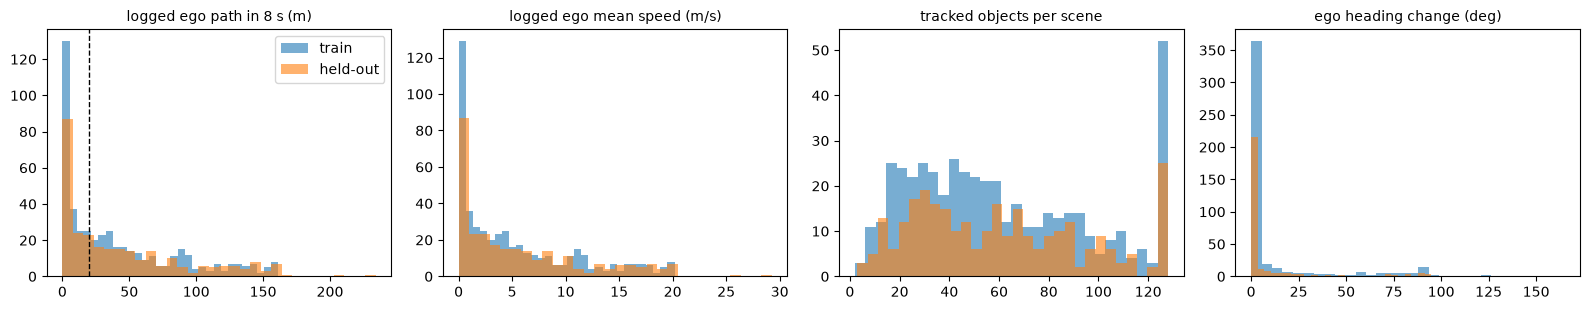

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for name, b in (("train", train_bank), ("held-out", val_bank)):
    m = b["meta"]
    axes[0].hist(m.log_len, bins=30, alpha=0.6, label=name)
    axes[1].hist(m.mean_speed, bins=30, alpha=0.6, label=name)
    axes[2].hist(m.objects, bins=30, alpha=0.6, label=name)
    axes[3].hist(m.turn_deg.clip(0, 180), bins=30, alpha=0.6, label=name)
for ax, t in zip(axes, ["logged ego path in 8 s (m)", "logged ego mean speed (m/s)",
                        "tracked objects per scene", "ego heading change (deg)"]):
    ax.set_title(t, fontsize=10)
axes[0].axvline(WAIT_THRESHOLD, color="k", ls="--", lw=1)
axes[0].legend()
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "data_overview.png"), dpi=130)
plt.show()

## 3. Environment

The ego is controlled through Waymax's `PlanningAgentEnvironment` with the invertible
bicycle model. The other objects either replay their logs or react to the ego as IDM
agents.

**Reactive traffic.** Waymax's `IDMRoutePolicy` ran at about 75 environment steps per
second with 64 objects on the 2-core machine we trained on (replay ran at about 3,000), which would have
made training against reactive traffic take more than seven hours per run. We wrote the
same behaviour as a vectorised Waymax actor (`make_reactive_idm` below): every car
follows its own logged path and sets its speed with the Intelligent Driver Model
(Treiber et al., 2000) from the nearest object ahead in its lane, the ego included.
Its desired speed is the highest speed it reached in its log. Unlike Waymax's policy,
a car is handed back to log replay when it reaches the end of its recorded path, so it
never drives straight off the map. It ran at about 2,200 steps per second there, and
section 9 checks it against Waymax's `IDMRoutePolicy` on the same scenes.

- **Observation (50 values).** Ego speed, heading error and lateral offset to the
  route, route progress, time left, last acceleration and curvature; five route points
  5–25 m ahead in the ego frame; the next traffic light on the route (distance, red
  or not, present); and for the 5 nearest objects their position and velocity relative
  to the ego, whether they are a pedestrian or cyclist, and a presence flag. Seeing only
  the nearest few objects makes the problem partially observable, as the proposal notes.
- **Action.** Normalised [acceleration, curvature] in [-1, 1], scaled to the bicycle
  model's bounds (±6 m/s², ±0.3 1/m printed above).
- **Reward.** `r = w_p·progress − w_c·collision − w_o·offroad − w_a·control`.
  Progress is the distance gained along the route as a percentage of the logged
  distance (at least 20 m), so following the human through a driving scene earns about
  100 per episode. Progress only counts up to 2 m ahead of where the logged car was at
  that moment: earlier runs without this cap learned to drive faster than the human
  and collided more, and with a 5 m margin they crept into stopped queues. The control
  term penalises jerk, curvature change and braking harder than 3 m/s².
- **Episode end.** Collision (Waymax overlap check), leaving the road (Waymax's
  off-road check run for the ego only; the stock metric checks every object and was
  about 100 times slower), or the end of the log after 80 steps. Because time left is
  part of the observation, the fixed horizon stays Markov.

Red-light running is measured (crossing an on-route stop line while it is red) but
not penalised, so it is an outcome we can compare across methods.

In [7]:
DT, MAX_ACCEL, MAX_KAPPA = 0.1, 6.0, 0.3
EPISODE_STEPS = LAST_STEP - INIT_STEP
LOOKAHEAD = (5.0, 10.0, 15.0, 20.0, 25.0)
NEIGHBOR_RANGE = 50.0
PROGRESS_LEAD = 2.0
MIN_ROUTE_LEN = 20.0


@dataclasses.dataclass(frozen=True)
class RewardConfig:
    w_progress: float = 1.0
    w_collision: float = 50.0
    w_offroad: float = 50.0
    w_control: float = 0.05
    w_red: float = 0.0        # crossing an on-route stop line on red (used in section 14)
    w_ttc: float = 0.0        # time-to-collision below 2 s with the object ahead (section 14)


REWARD_PRESETS = {
    "progress": RewardConfig(1.0, 10.0, 10.0, 0.02),
    "balanced": RewardConfig(1.0, 50.0, 50.0, 0.05),
    "safety": RewardConfig(1.0, 200.0, 200.0, 0.1),
    "improved": RewardConfig(1.0, 50.0, 50.0, 0.1, w_red=50.0, w_ttc=2.0),
}
TTC_LIMIT = 2.0


def wrap_angle(a):
    return jnp.arctan2(jnp.sin(a), jnp.cos(a))


def to_ego_frame(dx, dy, yaw):
    c, s = jnp.cos(yaw), jnp.sin(yaw)
    return c * dx + s * dy, -s * dx + c * dy


def project_to_route(route, valid, x, y):
    n = route.shape[0]
    d2 = jnp.where(valid, (route[:, 0] - x) ** 2 + (route[:, 1] - y) ** 2, jnp.inf)
    i = jnp.argmin(d2)
    i0 = jnp.clip(i, 0, n - 2)
    i0 = jnp.where(valid[jnp.clip(i0 + 1, 0, n - 1)], i0, jnp.maximum(i0 - 1, 0))
    t = route[i0 + 1] - route[i0]
    t = t / (jnp.linalg.norm(t) + 1e-6)
    rel = jnp.array([x, y]) - route[i0]
    along = jnp.clip(rel @ t, -ROUTE_SPACING, 2 * ROUTE_SPACING)
    return (i0 * ROUTE_SPACING + along, t[0] * rel[1] - t[1] * rel[0],
            jnp.arctan2(t[1], t[0]))


def point_at(route, valid, s):
    last = jnp.sum(valid) - 1
    f = jnp.clip(s / ROUTE_SPACING, 0.0, last.astype(jnp.float32))
    i0 = jnp.floor(f).astype(jnp.int32)
    i1 = jnp.minimum(i0 + 1, last)
    w = f - i0
    return route[i0] * (1 - w) + route[i1] * w


def make_reactive_idm(a_max=2.0, b_comf=4.0, min_gap=2.0, headway=1.5, delta=4.0):
    """IDM agents that follow their own logged paths.

    Same behaviour as Waymax's IDMRoutePolicy (path from the log, speed from the
    Intelligent Driver Model with the nearest object ahead, the ego included), written
    with plain (objects x objects) and (objects x time) array operations so it runs at
    replay speed. Each car's desired speed is the highest speed it reached in its log,
    and a car is handed back to log replay once it reaches the end of its logged path
    and its log has ended, so cars never drive off their recorded path.

    The actor state holds one flag, `reactive`. When it is False every car stays on log
    replay, which lets one environment mix replayed and reactive episodes.
    """
    def init(rng, state):
        return {"reactive": jnp.array(True)}

    def select_action(params, state, actor_state, rng):
        lt, traj = state.log_trajectory, state.current_sim_trajectory
        n, t = lt.x.shape[0], state.timestep
        x, y, yaw = traj.x[:, 0], traj.y[:, 0], traj.yaw[:, 0]
        vx, vy = traj.vel_x[:, 0], traj.vel_y[:, 0]
        v = jnp.hypot(vx, vy)
        valid_now = traj.valid[:, 0]
        lv = lt.valid
        seg_ok = lv[:, 1:] & lv[:, :-1]
        seg = jnp.hypot(jnp.diff(lt.x, axis=1), jnp.diff(lt.y, axis=1)) * seg_ok
        cs = jnp.concatenate([jnp.zeros((n, 1)), jnp.cumsum(seg, axis=1)], axis=1)
        last = 90 - jnp.argmax(lv[:, ::-1], axis=1)                    # last valid log index
        s_end = jnp.take_along_axis(cs, last[:, None], 1)[:, 0]

        # where each car is along its own path
        d2 = jnp.where(lv, (lt.x - x[:, None]) ** 2 + (lt.y - y[:, None]) ** 2, jnp.inf)
        i = jnp.argmin(d2, axis=1)
        i0 = jnp.minimum(i, jnp.maximum(last - 1, 0))
        take = lambda a, k: jnp.take_along_axis(a, k[:, None], 1)[:, 0]
        px0, py0 = take(lt.x, i0), take(lt.y, i0)
        tx, ty = take(lt.x, i0 + 1) - px0, take(lt.y, i0 + 1) - py0
        tl = jnp.hypot(tx, ty) + 1e-6
        along = jnp.clip(((x - px0) * tx + (y - py0) * ty) / tl, 0.0, tl)
        s_now = take(cs, i0) + along

        # leader: nearest valid object ahead in this car's lane
        c, sn = jnp.cos(yaw), jnp.sin(yaw)
        rx, ry = x[None, :] - x[:, None], y[None, :] - y[:, None]
        dx = rx * c[:, None] + ry * sn[:, None]
        dy = -rx * sn[:, None] + ry * c[:, None]
        width, length = traj.width[:, 0], traj.length[:, 0]
        lane = 0.5 * (width[:, None] + width[None, :]) + 0.3
        ahead = valid_now[None, :] & (dx > 0) & (jnp.abs(dy) < lane) & ~jnp.eye(n, dtype=bool)
        gap = jnp.where(ahead, dx - 0.5 * (length[:, None] + length[None, :]), jnp.inf)
        j = jnp.argmin(gap, axis=1)
        g = take(gap, j)
        v_lead = vx[j] * c + vy[j] * sn
        log_speed = jnp.where(lv, jnp.hypot(lt.vel_x, lt.vel_y), 0.0)
        v0 = jnp.maximum(log_speed.max(axis=1), 3.0)
        s_star = min_gap + v * headway + v * (v - v_lead) / (2.0 * jnp.sqrt(a_max * b_comf))
        inter = jnp.where(jnp.isfinite(g), (jnp.maximum(s_star, 0.0) / jnp.maximum(g, 0.1)) ** 2, 0.0)
        acc = jnp.clip(a_max * (1.0 - (v / v0) ** delta - inter), -8.0, a_max)
        v_new = jnp.maximum(v + acc * DT, 0.0)
        s_new = jnp.minimum(s_now + jnp.maximum(v * DT + 0.5 * acc * DT ** 2, 0.0), s_end)

        # back to x, y, yaw on the logged path
        k = jnp.clip(jnp.sum((cs <= s_new[:, None]) & lv, axis=1) - 1, 0, jnp.maximum(last - 1, 0))
        k = jnp.maximum(k, jnp.argmax(lv, axis=1))
        ax_, ay_ = take(lt.x, k), take(lt.y, k)
        bx_, by_ = take(lt.x, k + 1), take(lt.y, k + 1)
        seg_len = take(cs, k + 1) - take(cs, k)
        w = jnp.clip((s_new - take(cs, k)) / jnp.maximum(seg_len, 1e-6), 0.0, 1.0)
        nx, ny = ax_ + w * (bx_ - ax_), ay_ + w * (by_ - ay_)
        nyaw = jnp.where(seg_len > 0.05, jnp.arctan2(by_ - ay_, bx_ - ax_), yaw)
        data = jnp.stack([nx, ny, nyaw, v_new * jnp.cos(nyaw), v_new * jnp.sin(nyaw)], -1)

        log_next = jax.lax.dynamic_index_in_dim(lv, t + 1, axis=1, keepdims=False)
        on_path = s_now < s_end - 0.5
        controlled = ((~state.object_metadata.is_sdc) & valid_now & (lv.sum(1) >= 2) & (log_next | on_path)
                      & actor_state["reactive"])
        action = datatypes.Action(data=data, valid=controlled[:, None])
        return agents.WaymaxActorOutput(actor_state=actor_state, action=action, is_controlled=controlled)

    return agents.actor_core_factory(init, select_action, name="reactive_idm")


@struct.dataclass
class EnvState:
    sim: Any
    idx: jax.Array
    s: jax.Array
    speed: jax.Array
    accel: jax.Array
    kappa: jax.Array
    ep_return: jax.Array
    ep_steps: jax.Array


class DrivingEnv:
    """Single-agent driving on WOMD scenes through Waymax."""

    def __init__(self, bank, reward=REWARD_PRESETS["balanced"], traffic="replay",
                 ego_dynamics="bicycle", k_neighbors=5, idm_speed=15.0, road_points=0,
                 lead_features=False, lead_frame="ego"):
        self.states = jtu.tree_map(jnp.asarray, bank["states"])
        self.routes = {k: jnp.asarray(v) for k, v in bank["routes"].items()}
        self.num_scenarios = int(self.routes["route"].shape[0])
        self.num_objects = int(self.states.log_trajectory.x.shape[1])
        self.reward_cfg, self.traffic, self.k = reward, traffic, k_neighbors
        self.idm_speed, self.road_points = idm_speed, road_points
        self.lead_features = lead_features
        self.lead_frame = lead_frame
        cfg = dataclasses.replace(
            wcfg.EnvironmentConfig(), max_num_objects=self.num_objects,
            init_steps=INIT_STEP + 1, controlled_object=wcfg.ObjectType.SDC,
            metrics=wcfg.MetricsConfig(metrics_to_run=("overlap",)))
        dyn = (dynamics.InvertibleBicycleModel() if ego_dynamics == "bicycle"
               else dynamics.StateDynamics())
        actors = []
        if traffic in ("idm", "mixed"):
            actors = [make_reactive_idm()]
        elif traffic == "waymax_idm":            # Waymax's own IDM agents, for the check in section 9
            actors = [agents.IDMRoutePolicy(
                is_controlled_func=lambda s: ~s.object_metadata.is_sdc, desired_vel=idm_speed)]
        self.wenv = wenv.PlanningAgentEnvironment(
            dyn, cfg, sim_agent_actors=actors, sim_agent_params=[None] * len(actors))
        self.obs_dim = 7 + 2 * len(LOOKAHEAD) + 3 + 6 * self.k + 2 * road_points + 3 * lead_features

    def _scenario(self, idx):
        return jtu.tree_map(lambda a: a[idx], self.states)

    def _route(self, idx):
        return {k: v[idx] for k, v in self.routes.items()}

    @staticmethod
    def _sdc(sim):
        return jnp.argmax(sim.object_metadata.is_sdc)

    def _ego(self, sim):
        traj = sim.current_sim_trajectory
        i = self._sdc(sim)
        return traj.x[i, 0], traj.y[i, 0], traj.yaw[i, 0], traj.vel_x[i, 0], traj.vel_y[i, 0]

    def reset_idx(self, idx, reactive=True):
        idx = jnp.asarray(idx, jnp.int32)
        sim = self.wenv.reset(self._scenario(idx))
        if self.traffic == "mixed":
            sim = sim.replace(sim_agent_actor_states=[{"reactive": jnp.asarray(reactive)}])
        r = self._route(idx)
        x, y, _, vx, vy = self._ego(sim)
        s, _, _ = project_to_route(r["route"], r["route_valid"], x, y)
        zero = jnp.zeros((), jnp.float32)
        return EnvState(sim, idx, s, jnp.hypot(vx, vy), zero, zero, zero,
                        jnp.zeros((), jnp.int32))

    def reset(self, key):
        """A random scene. With mixed traffic the episode is replayed or reactive with
        equal probability."""
        idx = jax.random.randint(key, (), 0, self.num_scenarios)
        return self.reset_idx(idx, jax.random.bernoulli(jax.random.fold_in(key, 1)))

    def _next_light(self, r, s, t):
        """Distance to the next on-route signal ahead and whether it is red now."""
        ahead = r["tl_on"] & (r["tl_s"] > s - 1.0)
        dist = jnp.where(ahead, r["tl_s"] - s, jnp.inf)
        j = jnp.argmin(dist)
        red = jax.lax.dynamic_index_in_dim(r["tl_red"][j], t, keepdims=False)
        present = jnp.isfinite(dist[j])
        return jnp.where(present, dist[j], NEIGHBOR_RANGE), red & present, present

    def _neighbors(self, sim, x, y, yaw, vx, vy):
        traj = sim.current_sim_trajectory
        n = traj.x.shape[0]
        others = traj.valid[:, 0] & (jnp.arange(n) != self._sdc(sim))
        dx, dy = traj.x[:, 0] - x, traj.y[:, 0] - y
        d2 = jnp.where(others, dx ** 2 + dy ** 2, jnp.inf)
        order = jnp.argsort(d2)[: self.k]
        px, py = to_ego_frame(dx[order], dy[order], yaw)
        rvx, rvy = to_ego_frame(traj.vel_x[order, 0] - vx, traj.vel_y[order, 0] - vy, yaw)
        present = (d2[order] < NEIGHBOR_RANGE ** 2).astype(jnp.float32)
        vru = (sim.object_metadata.object_types[order] > 1).astype(jnp.float32)
        return dict(px=px, py=py, rvx=rvx, rvy=rvy, present=present, vru=vru,
                    length=traj.length[order, 0], width=traj.width[order, 0])

    def _road_edges(self, sim, x, y, yaw):
        rg = sim.roadgraph_points
        edge = rg.valid & jnp.isin(rg.types, jnp.array(ROAD_EDGE_TYPES))
        d2 = jnp.where(edge, (rg.x - x) ** 2 + (rg.y - y) ** 2, jnp.inf)
        _, idx = jax.lax.top_k(-d2, self.road_points)
        ex, ey = to_ego_frame(rg.x[idx] - x, rg.y[idx] - y, yaw)
        ok = jnp.isfinite(d2[idx])
        return jnp.stack([jnp.where(ok, ex / 25.0, 0.0), jnp.where(ok, ey / 25.0, 0.0)], -1)

    def _lead(self, sim, r, s, x, y, yaw, vx, vy):
        """Gap, closing speed and time to collision to whatever is directly ahead in the
        ego's lane: the nearest object within ±2 m laterally, or a red stop line."""
        traj = sim.current_sim_trajectory
        n = traj.x.shape[0]
        sdc = self._sdc(sim)
        others = traj.valid[:, 0] & (jnp.arange(n) != sdc)
        px, py = to_ego_frame(traj.x[:, 0] - x, traj.y[:, 0] - y, yaw)
        rvx, _ = to_ego_frame(traj.vel_x[:, 0] - vx, traj.vel_y[:, 0] - vy, yaw)
        ego_len = traj.length[sdc, 0]
        if self.lead_frame == "route":
            # measure along the route instead of along the ego's heading, so that steering
            # out of the lane does not make the vehicle ahead disappear
            so, lo, yo = jax.vmap(lambda a, b: project_to_route(r["route"], r["route_valid"], a, b))(
                traj.x[:, 0], traj.y[:, 0])
            _, _, ego_path_yaw = project_to_route(r["route"], r["route_valid"], x, y)
            ahead = others & (so > s) & (jnp.abs(lo) < 2.0)
            px = so - s
            ego_along = vx * jnp.cos(ego_path_yaw) + vy * jnp.sin(ego_path_yaw)
            obj_along = traj.vel_x[:, 0] * jnp.cos(yo) + traj.vel_y[:, 0] * jnp.sin(yo)
            rvx = obj_along - ego_along
        else:
            ahead = others & (px > 0) & (jnp.abs(py) < 2.0)
        gap = jnp.where(ahead, px - 0.5 * (traj.length[:, 0] + ego_len), jnp.inf)
        closing = -rvx
        tl_d, tl_red, _ = self._next_light(r, s, sim.timestep)
        gap = jnp.concatenate([gap, jnp.where(tl_red, tl_d - 0.5 * ego_len, jnp.inf)[None]])
        closing = jnp.concatenate([closing, jnp.hypot(vx, vy)[None]])
        j = jnp.argmin(gap)
        g = jnp.maximum(gap[j], 0.0)
        c = jnp.where(jnp.isfinite(gap[j]), closing[j], 0.0)
        ttc = jnp.where(c > 0.1, g / jnp.maximum(c, 0.1), 10.0)
        return jnp.where(jnp.isfinite(gap[j]), g, NEIGHBOR_RANGE), c, jnp.minimum(ttc, 10.0)

    def observe(self, es):
        sim, r = es.sim, self._route(es.idx)
        x, y, yaw, vx, vy = self._ego(sim)
        s, lat, path_yaw = project_to_route(r["route"], r["route_valid"], x, y)
        length = jnp.maximum(r["s_end"] - r["s_init"], MIN_ROUTE_LEN)
        look = []
        for d in LOOKAHEAD:
            p = point_at(r["route"], r["route_valid"], s + d)
            lx, ly = to_ego_frame(p[0] - x, p[1] - y, yaw)
            look += [lx / 25.0, ly / 25.0]
        tl_d, tl_red, tl_present = self._next_light(r, s, sim.timestep)
        nb = self._neighbors(sim, x, y, yaw, vx, vy)
        nb_feats = jnp.stack([nb["px"] / NEIGHBOR_RANGE, nb["py"] / NEIGHBOR_RANGE,
                              nb["rvx"] / 15.0, nb["rvy"] / 15.0, nb["vru"],
                              nb["present"]], -1) * nb["present"][:, None]
        feats = jnp.stack([es.speed / 15.0, wrap_angle(yaw - path_yaw),
                           jnp.clip(lat / 4.0, -3, 3), (s - r["s_init"]) / length,
                           (LAST_STEP - sim.timestep) / EPISODE_STEPS,
                           es.accel / MAX_ACCEL, es.kappa / MAX_KAPPA] + look
                          + [jnp.clip(tl_d, 0, NEIGHBOR_RANGE) / NEIGHBOR_RANGE,
                             tl_red.astype(jnp.float32), tl_present.astype(jnp.float32)])
        parts = [feats, nb_feats.reshape(-1)]
        if self.lead_features:
            g, c, ttc = self._lead(sim, r, s, x, y, yaw, vx, vy)
            parts.append(jnp.stack([jnp.clip(g, 0, NEIGHBOR_RANGE) / NEIGHBOR_RANGE,
                                    jnp.clip(c / 15.0, -2, 2), ttc / 10.0]))
        if self.road_points:
            parts.append(self._road_edges(sim, x, y, yaw).reshape(-1))
        return jnp.concatenate(parts).astype(jnp.float32)

    def _log_arclength(self, sim, r, t):
        i = self._sdc(sim)
        lx = jax.lax.dynamic_index_in_dim(sim.log_trajectory.x[i], t, keepdims=False)
        ly = jax.lax.dynamic_index_in_dim(sim.log_trajectory.y[i], t, keepdims=False)
        return project_to_route(r["route"], r["route_valid"], lx, ly)[0]

    def ego_offroad(self, sim):
        traj = datatypes.select_by_onehot(sim.current_sim_trajectory,
                                          sim.object_metadata.is_sdc, keepdims=True)
        return rg_metrics.is_offroad(traj, sim.roadgraph_points).reshape(())

    def bicycle_action(self, a_norm):
        a = jnp.clip(a_norm, -1.0, 1.0) * jnp.array([MAX_ACCEL, MAX_KAPPA])
        return datatypes.Action(data=a, valid=jnp.ones((1,), bool))

    def step(self, es, a_norm):
        return self.step_waymax(es, self.bicycle_action(a_norm))

    def step_waymax(self, es, action):
        cfg = self.reward_cfg
        sim = self.wenv.step(es.sim, action)
        collision = self.wenv.metrics(sim)["overlap"].value.reshape(()) > 0
        offroad = self.ego_offroad(sim)
        r = self._route(es.idx)
        x, y, yaw, vx, vy = self._ego(sim)
        prev_yaw = self._ego(es.sim)[2]
        s, lat, _ = project_to_route(r["route"], r["route_valid"], x, y)
        speed = jnp.hypot(vx, vy)
        accel = (speed - es.speed) / DT
        kappa = jnp.where(speed > 0.5, wrap_angle(yaw - prev_yaw) / (jnp.maximum(speed, 0.5) * DT), 0.0)
        jerk, dkappa = (accel - es.accel) / DT, kappa - es.kappa

        length = jnp.maximum(r["s_end"] - r["s_init"], MIN_ROUTE_LEN)
        cap_prev = self._log_arclength(es.sim, r, es.sim.timestep) + PROGRESS_LEAD
        cap_now = self._log_arclength(sim, r, sim.timestep) + PROGRESS_LEAD
        r_progress = 100.0 * (jnp.minimum(s, cap_now) - jnp.minimum(es.s, cap_prev)) / length
        harsh = jnp.maximum(0.0, -accel - 3.0) / 3.0
        control = jnp.clip((jerk / 10.0) ** 2 + (dkappa / 0.02) ** 2 + harsh, 0.0, 10.0)
        reward = (cfg.w_progress * r_progress - cfg.w_collision * collision
                  - cfg.w_offroad * offroad - cfg.w_control * control)

        # red light: crossing an on-route stop line while it is red
        crossed = r["tl_on"] & (es.s < r["tl_s"]) & (s >= r["tl_s"])
        red_now = jax.lax.dynamic_index_in_dim(r["tl_red"], sim.timestep, axis=1, keepdims=False)
        ran_red = jnp.any(crossed & red_now)
        _, _, ttc = self._lead(sim, r, s, x, y, yaw, vx, vy)
        reward = (reward - cfg.w_red * ran_red
                  - cfg.w_ttc * jnp.clip((TTC_LIMIT - ttc) / TTC_LIMIT, 0.0, 1.0) * (speed > 0.5))

        done = collision | offroad | (sim.timestep >= LAST_STEP)
        es2 = EnvState(sim, es.idx, s, speed, accel, kappa, es.ep_return + reward, es.ep_steps + 1)
        nb = self._neighbors(sim, x, y, yaw, vx, vy)
        info = dict(done=done, collision=collision, offroad=offroad, ran_red=ran_red,
                    covered=s - r["s_init"], progress=(s - r["s_init"]) / length,
                    ep_return=es2.ep_return, x=x, y=y, yaw=yaw, speed=speed, accel=accel,
                    kappa=kappa, jerk=jerk, dkappa=dkappa, lat=lat,
                    route_kappa=r["route_kappa"][jnp.clip(jnp.round(s).astype(jnp.int32), 0, ROUTE_POINTS - 1)],
                    near_dx=nb["px"][0], near_dy=nb["py"][0], near_rvx=nb["rvx"][0],
                    near_vru=nb["vru"][0], near_len=nb["length"][0], ttc=ttc, reward=reward)
        return es2, self.observe(es2), reward, done, info

    def pure_pursuit(self, es, lookahead_gain=0.8, max_speed=15.0, headway=1.5,
                     min_gap=2.0, a_max=2.0, b_comf=3.0):
        """Hand-designed controller: pure pursuit on the route, IDM-style speed
        control behind the nearest object ahead, and a stop at red lights."""
        r = self._route(es.idx)
        x, y, yaw, vx, vy = self._ego(es.sim)
        v = jnp.hypot(vx, vy)
        ld = jnp.clip(4.0 + lookahead_gain * v, 5.0, 20.0)
        p = point_at(r["route"], r["route_valid"], es.s + ld)
        lx, ly = to_ego_frame(p[0] - x, p[1] - y, yaw)
        kappa = 2.0 * ly / jnp.maximum(lx ** 2 + ly ** 2, 1.0)
        v0 = jnp.clip(jnp.mean(r["log_speed"][INIT_STEP:]) + 1.0, 3.0, max_speed)

        nb = self._neighbors(es.sim, x, y, yaw, vx, vy)
        ego_len = es.sim.current_sim_trajectory.length[self._sdc(es.sim), 0]
        ahead = (nb["present"] > 0) & (nb["px"] > 0) & (jnp.abs(nb["py"]) < 2.0)
        gap = jnp.where(ahead, nb["px"] - 0.5 * (nb["length"] + ego_len), jnp.inf)
        dv = -nb["rvx"]
        # a red light ahead acts like a stopped car at the stop line
        tl_d, tl_red, _ = self._next_light(r, es.s, es.sim.timestep)
        gap = jnp.concatenate([gap, jnp.where(tl_red, tl_d - 0.5 * ego_len, jnp.inf)[None]])
        dv = jnp.concatenate([dv, v[None]])
        j = jnp.argmin(gap)
        s_star = min_gap + v * headway + v * dv[j] / (2.0 * jnp.sqrt(a_max * b_comf))
        inter = jnp.where(jnp.isfinite(gap[j]),
                          (jnp.maximum(s_star, 0.0) / jnp.maximum(gap[j], 0.1)) ** 2, 0.0)
        accel = jnp.clip(a_max * (1.0 - (v / v0) ** 4 - inter), -MAX_ACCEL, a_max)
        return jnp.array([accel / MAX_ACCEL, kappa / MAX_KAPPA])

    def expert_action(self, es):
        """The logged human trajectory (state dynamics)."""
        sim, i = es.sim, self._sdc(es.sim)
        lt, t = sim.log_trajectory, sim.timestep + 1
        get = lambda a: jax.lax.dynamic_index_in_dim(a[i], t, keepdims=False)
        return datatypes.Action(data=jnp.stack([get(lt.x), get(lt.y), get(lt.yaw),
                                                get(lt.vel_x), get(lt.vel_y)]),
                                valid=jnp.ones((1,), bool))

    def idm_ego_action(self, es):
        """Waymax's IDM route-following policy driving the ego (state dynamics)."""
        if not hasattr(self, "_idm_ego"):
            self._idm_ego = agents.IDMRoutePolicy(
                is_controlled_func=lambda s: s.object_metadata.is_sdc, desired_vel=self.idm_speed)
        out = self._idm_ego.select_action(None, es.sim, None, None)
        i = self._sdc(es.sim)
        return datatypes.Action(data=out.action.data[i], valid=out.action.valid[i])

    def expert_bicycle_action(self, es):
        """Bicycle action that reproduces the next logged step (inverse dynamics),
        normalised to [-1, 1]; used for behaviour cloning."""
        sim, i = es.sim, self._sdc(es.sim)
        act = dynamics.InvertibleBicycleModel().inverse(sim.log_trajectory, sim.object_metadata,
                                                        sim.timestep)
        return act.data[i] / jnp.array([MAX_ACCEL, MAX_KAPPA])


env_check = DrivingEnv(val_bank)
print("observation size:", env_check.obs_dim)

observation size: 50


### Sanity checks

Before training anything we check the wrapper with the logged human trajectory, which
should almost never collide, leave the road or run a red light, and should earn about
100 progress per driving episode. We also measure how fast the environment runs.

In [8]:
def rollout(env, act, idx):
    """Runs every scenario in idx for the full horizon. Returns per-step arrays of
    shape (scenes, 80); `alive` marks steps up to and including the one that ended
    the episode."""

    @jax.jit
    def run(idx):
        es = jax.vmap(env.reset_idx)(idx)
        obs = jax.vmap(env.observe)(es)

        def body(carry, _):
            es, obs, alive = carry
            es2, obs2, _, done, info = jax.vmap(env.step_waymax)(es, jax.vmap(act)(es, obs))
            return (es2, obs2, alive & ~done), dict(info, alive=alive)

        _, infos = jax.lax.scan(body, (es, obs, jnp.ones(idx.shape, bool)), None, EPISODE_STEPS)
        return jtu.tree_map(lambda a: jnp.swapaxes(a, 0, 1), infos)

    return {k: np.asarray(v) for k, v in jax.device_get(run(jnp.asarray(idx))).items()}


def rollout_all(env, act, batch=48):
    n = env.num_scenarios
    parts = []
    for start in range(0, n, batch):
        idx = np.arange(start, min(start + batch, n))
        pad = np.concatenate([idx, np.full(batch - len(idx), idx[-1])]) if len(idx) < batch else idx
        roll = rollout(env, act, pad)
        parts.append({k: v[: len(idx)] for k, v in roll.items()})
    return {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}


env_state = DrivingEnv(val_bank, ego_dynamics="state")
t0 = time.time()
check = rollout_all(env_state, lambda es, obs: env_state.expert_action(es))
alive = check["alive"]
driving = (val_bank["meta"].kind == "driving").values
prog_reward = np.where(alive, check["reward"], 0).sum(1)
print(f"logged human on {len(alive)} held-out scenes ({time.time() - t0:.0f}s):")
print(f"  collision {100 * (check['collision'] & alive).any(1).mean():.1f}%  "
      f"off-road {100 * (check['offroad'] & alive).any(1).mean():.1f}%  "
      f"ran red {100 * (check['ran_red'] & alive).any(1).mean():.1f}%")
print(f"  mean episode reward, driving scenes: {prog_reward[driving].mean():.1f}")

N_BENCH = 64
es_b = jax.vmap(env_check.reset)(jax.random.split(jax.random.PRNGKey(0), N_BENCH))
step_b = jax.jit(jax.vmap(env_check.step))
es_b = step_b(es_b, jnp.zeros((N_BENCH, 2)))[0]
jax.block_until_ready(es_b.s)
t0 = time.time()
for _ in range(20):
    es_b = step_b(es_b, jnp.zeros((N_BENCH, 2)))[0]
jax.block_until_ready(es_b.s)
print(f"environment throughput: {N_BENCH * 20 / (time.time() - t0):.0f} steps/s on {jax.devices()[0].platform}")

logged human on 288 held-out scenes (9s):
  collision 0.3%  off-road 1.7%  ran red 1.4%
  mean episode reward, driving scenes: 97.9


environment throughput: 20690 steps/s on cpu


## 4. PPO

A Gaussian actor and an MLP critic (two hidden layers of 256, tanh), trained with the
clipped surrogate, GAE, advantage normalisation, value loss, gradient clipping and a
linearly annealed learning rate, following CleanRL's `ppo_continuous_action.py`.
Rollouts are a `jax.lax.scan` over vmapped environments, so one update is one compiled
function. Observations are normalised with running statistics. The initial policy
standard deviation is e^-1.6 ≈ 0.2 in normalised action units: with our first choice,
e^-0.5 ≈ 0.6, the steering noise alone made the car weave and training stalled near
40 % collisions.
Finished episodes are reset to a new random scene inside the scan.

In [9]:
@dataclasses.dataclass
class PPOConfig:
    num_envs: int = 64
    num_steps: int = 64
    total_timesteps: int = TOTAL_STEPS
    lr: float = 3e-4
    gamma: float = 0.99
    gae_lambda: float = 0.95
    update_epochs: int = 4
    num_minibatches: int = 8
    clip_eps: float = 0.2
    ent_coef: float = 0.0
    vf_coef: float = 0.5
    max_grad_norm: float = 0.5
    hidden: int = 256
    log_std_init: float = -1.6
    reward_scale: float = 0.1

    @property
    def batch_size(self):
        return self.num_envs * self.num_steps

    @property
    def num_updates(self):
        return max(self.total_timesteps // self.batch_size, 1)


class ActorCritic(nn.Module):
    hidden: int = 256
    log_std_init: float = -1.6

    @nn.compact
    def __call__(self, x):
        ortho = nn.initializers.orthogonal
        a = nn.tanh(nn.Dense(self.hidden, kernel_init=ortho(np.sqrt(2)))(x))
        a = nn.tanh(nn.Dense(self.hidden, kernel_init=ortho(np.sqrt(2)))(a))
        mean = nn.Dense(2, kernel_init=ortho(0.01))(a)
        log_std = self.param("log_std", nn.initializers.constant(self.log_std_init), (2,))
        v = nn.tanh(nn.Dense(self.hidden, kernel_init=ortho(np.sqrt(2)))(x))
        v = nn.tanh(nn.Dense(self.hidden, kernel_init=ortho(np.sqrt(2)))(v))
        return mean, log_std, nn.Dense(1, kernel_init=ortho(1.0))(v)[..., 0]


def gaussian_logp(x, mean, log_std):
    return jnp.sum(-0.5 * ((x - mean) / jnp.exp(log_std)) ** 2 - log_std
                   - 0.5 * jnp.log(2 * jnp.pi), axis=-1)


@struct.dataclass
class ObsNorm:
    mean: jax.Array
    var: jax.Array
    count: jax.Array

    @staticmethod
    def create(dim):
        return ObsNorm(jnp.zeros(dim), jnp.ones(dim), jnp.array(1e-4))

    def update(self, x):
        x = x.reshape(-1, x.shape[-1])
        bm, bv, bn = x.mean(0), x.var(0), x.shape[0]
        delta, tot = bm - self.mean, self.count + bn
        m2 = self.var * self.count + bv * bn + delta ** 2 * self.count * bn / tot
        return ObsNorm(self.mean + delta * bn / tot, m2 / tot, tot)

    def __call__(self, x):
        return jnp.clip((x - self.mean) / jnp.sqrt(self.var + 1e-8), -10, 10)


@struct.dataclass
class Runner:
    train_state: TrainState
    obs_norm: ObsNorm
    env_state: Any
    obs: jax.Array
    key: jax.Array


def make_trainer(env, cfg):
    net = ActorCritic(cfg.hidden, cfg.log_std_init)

    def lr_schedule(count):
        return cfg.lr * (1.0 - (count // (cfg.num_minibatches * cfg.update_epochs)) / cfg.num_updates)

    def init(key, params=None, obs_norm=None):
        k_net, k_env, key = jax.random.split(key, 3)
        if params is None:
            params = net.init(k_net, jnp.zeros((env.obs_dim,)))
        tx = optax.chain(optax.clip_by_global_norm(cfg.max_grad_norm),
                         optax.adam(lr_schedule, eps=1e-5))
        ts = TrainState.create(apply_fn=net.apply, params=params, tx=tx)
        es = jax.vmap(env.reset)(jax.random.split(k_env, cfg.num_envs))
        return Runner(ts, obs_norm if obs_norm is not None else ObsNorm.create(env.obs_dim),
                      es, jax.vmap(env.observe)(es), key)

    def env_step(runner, _):
        key, k_act, k_reset = jax.random.split(runner.key, 3)
        mean, log_std, value = net.apply(runner.train_state.params, runner.obs_norm(runner.obs))
        action = mean + jnp.exp(log_std) * jax.random.normal(k_act, mean.shape)
        logp = gaussian_logp(action, mean, log_std)
        es2, obs2, reward, done, info = jax.vmap(env.step)(runner.env_state, action)
        fresh = jax.vmap(env.reset)(jax.random.split(k_reset, cfg.num_envs))
        fresh_obs = jax.vmap(env.observe)(fresh)
        pick = lambda a, b: jnp.where(done.reshape((-1,) + (1,) * (a.ndim - 1)), a, b)
        tr = dict(obs=runner.obs, action=action, logp=logp, value=value,
                  reward=reward * cfg.reward_scale, done=done, ep_return=info["ep_return"],
                  collision=info["collision"], offroad=info["offroad"], progress=info["progress"])
        return runner.replace(env_state=jtu.tree_map(pick, fresh, es2),
                              obs=pick(fresh_obs, obs2), key=key), tr

    def gae(traj, last_value):
        def body(carry, t):
            adv, next_value = carry
            nonterm = 1.0 - t["done"]
            delta = t["reward"] + cfg.gamma * next_value * nonterm - t["value"]
            adv = delta + cfg.gamma * cfg.gae_lambda * nonterm * adv
            return (adv, t["value"]), adv

        _, adv = jax.lax.scan(body, (jnp.zeros_like(last_value), last_value), traj, reverse=True)
        return adv, adv + traj["value"]

    def loss_fn(params, obs_norm, mb):
        mean, log_std, value = net.apply(params, obs_norm(mb["obs"]))
        ratio = jnp.exp(gaussian_logp(mb["action"], mean, log_std) - mb["logp"])
        adv = (mb["adv"] - mb["adv"].mean()) / (mb["adv"].std() + 1e-8)
        pg = -jnp.minimum(ratio * adv, jnp.clip(ratio, 1 - cfg.clip_eps, 1 + cfg.clip_eps) * adv).mean()
        v_loss = 0.5 * ((value - mb["ret"]) ** 2).mean()
        entropy = jnp.sum(log_std + 0.5 * jnp.log(2 * jnp.pi * jnp.e))
        return pg + cfg.vf_coef * v_loss - cfg.ent_coef * entropy, dict(
            pg_loss=pg, v_loss=v_loss, entropy=entropy,
            approx_kl=((ratio - 1) - jnp.log(ratio)).mean())

    @jax.jit
    def update(runner):
        runner, traj = jax.lax.scan(env_step, runner, None, cfg.num_steps)
        obs_norm = runner.obs_norm.update(traj["obs"])
        last_value = net.apply(runner.train_state.params, runner.obs_norm(runner.obs))[2]
        adv, ret = gae(traj, last_value)
        batch = dict(obs=traj["obs"], action=traj["action"], logp=traj["logp"], adv=adv, ret=ret)
        batch = jtu.tree_map(lambda a: a.reshape((cfg.batch_size,) + a.shape[2:]), batch)

        def epoch(carry, _):
            ts, key = carry
            key, k = jax.random.split(key)
            perm = jax.random.permutation(k, cfg.batch_size)
            mbs = jtu.tree_map(lambda a: a[perm].reshape((cfg.num_minibatches, -1) + a.shape[1:]), batch)

            def minibatch(ts, mb):
                (_, aux), grads = jax.value_and_grad(loss_fn, has_aux=True)(ts.params, runner.obs_norm, mb)
                return ts.apply_gradients(grads=grads), aux

            ts, aux = jax.lax.scan(minibatch, ts, mbs)
            return (ts, key), aux

        (ts, key), aux = jax.lax.scan(epoch, (runner.train_state, runner.key), None, cfg.update_epochs)
        d = traj["done"]
        n = jnp.maximum(d.sum(), 1)
        stats = dict(episodes=d.sum(), ep_return=(traj["ep_return"] * d).sum() / n,
                     collision=(traj["collision"] * d).sum() / n,
                     offroad=(traj["offroad"] * d).sum() / n,
                     progress=(traj["progress"] * d).sum() / n, **jtu.tree_map(jnp.mean, aux))
        return runner.replace(train_state=ts, obs_norm=obs_norm, key=key), stats

    return net, init, update


def save_checkpoint(path, runner, u, cfg):
    blob = dict(params=jax.device_get(runner.train_state.params),
                opt_state=jax.device_get(runner.train_state.opt_state),
                obs_norm=jax.device_get(runner.obs_norm), update=u,
                config=dataclasses.asdict(cfg))
    with open(path + ".tmp", "wb") as f:
        pickle.dump(blob, f)
    os.replace(path + ".tmp", path)


def load_checkpoint(path):
    with open(path, "rb") as f:
        return pickle.load(f)


def train_ppo(env, cfg, seed, run_dir, init_params=None, init_obs_norm=None, log_every=50):
    """Trains PPO into run_dir (progress.csv + checkpoint.pkl); resumes or skips if done."""
    os.makedirs(run_dir, exist_ok=True)
    ckpt_path = os.path.join(run_dir, "checkpoint.pkl")
    log_path = os.path.join(run_dir, "progress.csv")
    _, init, update = make_trainer(env, cfg)
    runner = init(jax.random.PRNGKey(seed), init_params, init_obs_norm)
    start = 0
    if os.path.exists(ckpt_path):
        ck = load_checkpoint(ckpt_path)
        if ck["update"] >= cfg.num_updates:
            print(f"{run_dir}: already trained ({ck['update']} updates)")
            return
        ts = runner.train_state.replace(params=ck["params"], opt_state=ck["opt_state"],
                                        step=ck["update"] * cfg.num_minibatches * cfg.update_epochs)
        runner, start = runner.replace(train_state=ts, obs_norm=ck["obs_norm"]), ck["update"]
        print(f"{run_dir}: resuming at update {start}")
    if start == 0:
        with open(log_path, "w") as f:
            f.write("update,env_steps,wall_s,episodes,ep_return,collision,offroad,progress,"
                    "pg_loss,v_loss,entropy,approx_kl\n")
    t0 = time.time()
    for u in range(start, cfg.num_updates):
        runner, st = update(runner)
        st = {k: float(v) for k, v in jax.device_get(st).items()}
        with open(log_path, "a") as f:
            f.write(f"{u + 1},{(u + 1) * cfg.batch_size},{time.time() - t0:.1f},{st['episodes']:.0f},"
                    f"{st['ep_return']:.3f},{st['collision']:.4f},{st['offroad']:.4f},{st['progress']:.4f},"
                    f"{st['pg_loss']:.4f},{st['v_loss']:.4f},{st['entropy']:.4f},{st['approx_kl']:.5f}\n")
        if (u + 1) % log_every == 0 or u + 1 == cfg.num_updates:
            print(f"  {os.path.basename(run_dir)} [{u + 1}/{cfg.num_updates}] ret={st['ep_return']:.1f} "
                  f"coll={st['collision']:.3f} off={st['offroad']:.3f} prog={st['progress']:.2f} "
                  f"({time.time() - t0:.0f}s)", flush=True)
        if (u + 1) % 25 == 0 or u + 1 == cfg.num_updates:
            save_checkpoint(ckpt_path, runner, u + 1, cfg)


def load_policy(run_dir):
    ck = load_checkpoint(os.path.join(run_dir, "checkpoint.pkl"))
    net = ActorCritic(ck["config"]["hidden"], ck["config"]["log_std_init"])
    on = ck["obs_norm"]
    on = ObsNorm(jnp.asarray(on.mean), jnp.asarray(on.var), jnp.asarray(on.count))
    params = ck["params"]
    return lambda obs: net.apply(params, on(obs))[0]

## 5. First result: one scene end to end (proposal §3.4)

The proposal's first milestone: load one scene, build the observation, roll out the
hand-designed controller, then train PPO on that single scene until it reliably
reaches the end of the route without crashing.

scene: training_tfexample.tfrecord-00000-of-01000#21 | logged path 28 m, turn 50 deg, 14 objects within 30 m


hand-designed controller: collision=False offroad=False covered=30 m of 28 m


./runs/single_scene: already trained (156 updates)


PPO after 200000 steps: collision=False offroad=False covered=31 m


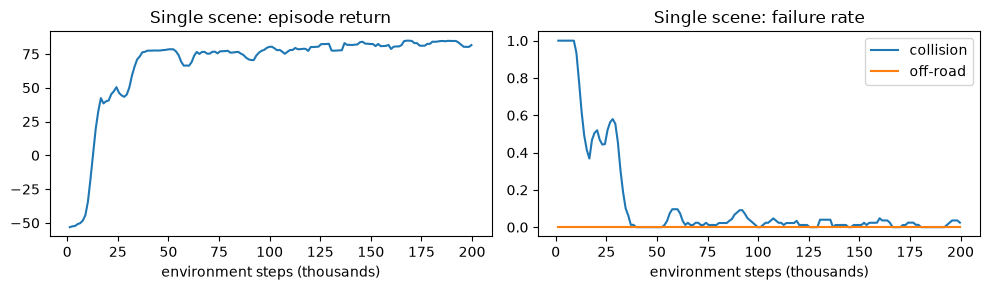

In [10]:
def subset_bank(bank, idx):
    idx = np.asarray(idx)
    return dict(states=jtu.tree_map(lambda a: a[idx], bank["states"]),
                routes={k: v[idx] for k, v in bank["routes"].items()},
                meta=bank["meta"].iloc[idx].reset_index(drop=True))


tm = train_bank["meta"]
cand = tm[(tm.kind == "driving") & (tm.near30 >= 5) & (tm.turn_deg > 20)]
one_idx = int(cand.index[0] if len(cand) else tm.index[0])
one_bank = subset_bank(train_bank, [one_idx])
print("scene:", tm.scenario[one_idx], f"| logged path {tm.log_len[one_idx]:.0f} m, "
      f"turn {tm.turn_deg[one_idx]:.0f} deg, {tm.near30[one_idx]} objects within 30 m")
env_one = DrivingEnv(one_bank)
pp_one = rollout(env_one, lambda es, obs: env_one.bicycle_action(env_one.pure_pursuit(es)), np.zeros(1, int))
a = pp_one["alive"][0]
print(f"hand-designed controller: collision={bool((pp_one['collision'][0] & a).any())} "
      f"offroad={bool((pp_one['offroad'][0] & a).any())} covered={pp_one['covered'][0][a][-1]:.0f} m "
      f"of {tm.log_len[one_idx]:.0f} m")

one_cfg = PPOConfig(num_envs=16, num_steps=80, total_timesteps=200_000 if not SMOKE else 2_560)
train_ppo(env_one, one_cfg, 0, os.path.join(RUNS_DIR, "single_scene"), log_every=40)
one_log = pd.read_csv(os.path.join(RUNS_DIR, "single_scene", "progress.csv"))
pol_one = load_policy(os.path.join(RUNS_DIR, "single_scene"))
ppo_one = rollout(env_one, lambda es, obs: env_one.bicycle_action(pol_one(obs)), np.zeros(1, int))
a = ppo_one["alive"][0]
print(f"PPO after {one_cfg.total_timesteps} steps: collision={bool((ppo_one['collision'][0] & a).any())} "
      f"offroad={bool((ppo_one['offroad'][0] & a).any())} covered={ppo_one['covered'][0][a][-1]:.0f} m")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(one_log.env_steps / 1e3, one_log.ep_return.rolling(5, min_periods=1).mean())
ax[0].set_xlabel("environment steps (thousands)")
ax[0].set_title("Single scene: episode return")
ax[1].plot(one_log.env_steps / 1e3, one_log.collision.rolling(5, min_periods=1).mean(), label="collision")
ax[1].plot(one_log.env_steps / 1e3, one_log.offroad.rolling(5, min_periods=1).mean(), label="off-road")
ax[1].set_xlabel("environment steps (thousands)")
ax[1].set_title("Single scene: failure rate")
ax[1].legend()
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "single_scene.png"), dpi=130)
plt.show()

## 6. Training

All runs use 2M environment steps, 64 parallel environments × 64 steps per update and
the same PPO settings; only the reward preset, the traffic model during training and
the seed change. Runs are skipped when a finished checkpoint already exists.

| Runs | Reward | Training traffic | Seeds | Purpose |
|---|---|---|---|---|
| `balanced_s*` | balanced (50/50) | replay | 3 | main comparison (H1) |
| `progress_s*`, `safety_s*` | 10/10, 200/200 | replay | 3 each | reward study (H3) |
| `idmtrained_s*` | balanced | reactive IDM | 3 | reactive traffic (H2) |

In [11]:
RUN_SPECS = []
for seed in SEEDS:
    for preset in ("balanced", "progress", "safety"):
        RUN_SPECS.append(dict(name=f"{preset}_s{seed}", reward=preset, traffic="replay", seed=seed))
    RUN_SPECS.append(dict(name=f"idmtrained_s{seed}", reward="balanced", traffic="idm", seed=seed))

cfg_main = PPOConfig()
print(f"{len(RUN_SPECS)} runs x {cfg_main.num_updates} updates ({cfg_main.total_timesteps:,} steps each)")
for spec in RUN_SPECS:
    env_train = DrivingEnv(train_bank, REWARD_PRESETS[spec["reward"]], traffic=spec["traffic"])
    train_ppo(env_train, cfg_main, spec["seed"], os.path.join(RUNS_DIR, spec["name"]))

12 runs x 488 updates (2,000,000 steps each)


./runs/balanced_s0: already trained (488 updates)
./runs/progress_s0: already trained (488 updates)


./runs/safety_s0: already trained (488 updates)
./runs/idmtrained_s0: already trained (488 updates)


./runs/balanced_s1: already trained (488 updates)
./runs/progress_s1: already trained (488 updates)


./runs/safety_s1: already trained (488 updates)
./runs/idmtrained_s1: already trained (488 updates)


./runs/balanced_s2: already trained (488 updates)
./runs/progress_s2: already trained (488 updates)


./runs/safety_s2: already trained (488 updates)
./runs/idmtrained_s2: already trained (488 updates)


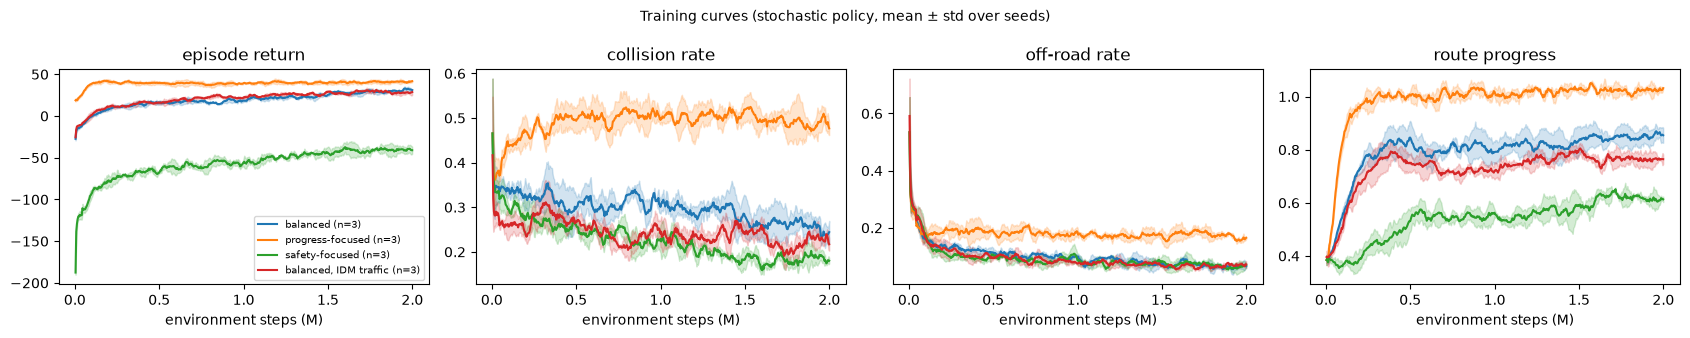

In [12]:
def run_logs(prefix):
    return [pd.read_csv(p) for p in sorted(glob.glob(os.path.join(RUNS_DIR, f"{prefix}_s*", "progress.csv")))]


fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for prefix, label, color in (("balanced", "balanced", "C0"), ("progress", "progress-focused", "C1"),
                             ("safety", "safety-focused", "C2"), ("idmtrained", "balanced, IDM traffic", "C3")):
    logs = run_logs(prefix)
    if not logs:
        continue
    n = min(len(lg) for lg in logs)
    x = logs[0].env_steps.values[:n] / 1e6
    for ax, col in zip(axes, ["ep_return", "collision", "offroad", "progress"]):
        ys = np.stack([lg[col].rolling(10, min_periods=1).mean().values[:n] for lg in logs])
        ax.plot(x, ys.mean(0), color=color, label=f"{label} (n={len(logs)})")
        ax.fill_between(x, ys.mean(0) - ys.std(0), ys.mean(0) + ys.std(0), color=color, alpha=0.2)
for ax, t in zip(axes, ["episode return", "collision rate", "off-road rate", "route progress"]):
    ax.set_title(t)
    ax.set_xlabel("environment steps (M)")
axes[0].legend(fontsize=7)
fig.suptitle("Training curves (stochastic policy, mean ± std over seeds)", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "learning_curves.png"), dpi=130)
plt.show()

## 7. Evaluation protocol

Every method runs on the same 288 held-out scenes (validation shard, never used for
training), with deterministic policies (the actor's mean). Metrics per episode:

- **collision**, **off-road**, **ran red light** (any time in the episode);
- **route progress** = distance covered along the route ÷ logged distance (at least
  20 m), and **success** = no collision, no off-road event and at least 80 % of the
  distance the human covered (minus 1 m), which works for driving and waiting scenes;
- **return** under the balanced reward, **mean |jerk|** (m/s³) and **mean |Δκ|**
  (1/m per step) from the realised trajectory, skipping the first two steps.

Failures are sorted into types at the step they happen:

- *struck from behind*: the nearest object is behind the ego (a replayed car driving
  into a slower ego, not the ego's fault);
- *collision while turning*: route or ego curvature above 0.02 1/m;
- *rear-end*: the nearest object is ahead within ±2 m laterally;
- *other collision*; *off-road on a curve* / *off-road on a straight*;
- *stalled*: no failure but less than half of the logged distance covered in a
  driving scene.

In [13]:
CURVE_KAPPA = 0.02


def classify(r, t, coll, off, stalled):
    if coll:
        dx, dy = r["near_dx"][t], r["near_dy"][t]
        if dx < 0 and abs(dy) < 2.0:
            return "struck_from_behind"
        if abs(r["route_kappa"][t]) > CURVE_KAPPA or abs(r["kappa"][t]) > CURVE_KAPPA:
            return "collision_turning"
        if dx > 0 and abs(dy) < 2.0:
            return "rear_end"
        return "collision_other"
    if off:
        return "offroad_curve" if abs(r["route_kappa"][t]) > CURVE_KAPPA else "offroad_straight"
    return "stalled" if stalled else "none"


def episode_table(roll, meta):
    rows = []
    for i in range(roll["alive"].shape[0]):
        r = {k: v[i] for k, v in roll.items()}
        alive = r["alive"]
        steps = int(alive.sum())
        last = steps - 1
        coll = bool((r["collision"] & alive).any())
        off = bool((r["offroad"] & alive).any())
        covered = float(r["covered"][last])
        log_len = float(meta.log_len[i])
        reached = covered >= 0.8 * log_len - 1.0
        stalled = (not coll) and (not off) and meta.kind[i] == "driving" and covered < 0.5 * log_len
        smooth = alive.copy()
        smooth[:2] = False
        ns = max(int(smooth.sum()), 1)
        rows.append(dict(
            scenario=meta.scenario[i], kind=meta.kind[i], turning=bool(meta.turning[i]),
            intersection=bool(meta.intersection[i]),
            steps=steps, ep_return=float((r["reward"] * alive).sum()),
            collision=coll, offroad=off, ran_red=bool((r["ran_red"] & alive).any()),
            progress=float(r["progress"][last]), covered_m=covered, logged_m=log_len,
            success=(not coll) and (not off) and reached,
            mean_abs_jerk=float(np.abs(r["jerk"] * smooth).sum() / ns),
            mean_abs_dkappa=float(np.abs(r["dkappa"] * smooth).sum() / ns),
            mean_speed=float((r["speed"] * alive).sum() / max(steps, 1)),
            failure=classify(r, last, coll, off, stalled),
            hit_vru=bool(coll and r["near_vru"][last] > 0),
            fail_speed=float(r["speed"][last]) if (coll or off) else np.nan,
            fail_gap=float(np.hypot(r["near_dx"][last], r["near_dy"][last])) if coll else np.nan))
    return pd.DataFrame(rows)


def make_actor(env, method, policy=None):
    if method == "ppo":
        return lambda es, obs: env.bicycle_action(policy(obs))
    if method == "pure_pursuit":
        return lambda es, obs: env.bicycle_action(env.pure_pursuit(es))
    if method == "idm_ego":
        return lambda es, obs: env.idm_ego_action(es)
    if method == "expert":
        return lambda es, obs: env.expert_action(es)
    raise ValueError(method)


def evaluate(method, traffic, bank=val_bank, run=None, env_kwargs=None, tag=None):
    """Evaluates one method (or one PPO run) and caches the per-scene CSV."""
    name = tag or (run if run else method)
    out = os.path.join(RESULTS_DIR, traffic, f"{name}.csv")
    if os.path.exists(out):
        return pd.read_csv(out)
    os.makedirs(os.path.dirname(out), exist_ok=True)
    dyn = "state" if method in ("expert", "idm_ego") else "bicycle"
    env = DrivingEnv(bank, REWARD_PRESETS["balanced"], traffic=traffic, ego_dynamics=dyn,
                     **(env_kwargs or {}))
    policy = load_policy(os.path.join(RUNS_DIR, run)) if run else None
    t0 = time.time()
    df = episode_table(rollout_all(env, make_actor(env, method, policy)), bank["meta"])
    df.to_csv(out, index=False)
    print(f"  {traffic:6s} {name:16s} coll={df.collision.mean():.3f} off={df.offroad.mean():.3f} "
          f"succ={df.success.mean():.3f} ({time.time() - t0:.0f}s)", flush=True)
    return df


for traffic in ("replay", "idm"):
    for method in ("expert", "idm_ego", "pure_pursuit"):
        evaluate(method, traffic)
    for spec in RUN_SPECS:
        evaluate("ppo", traffic, run=spec["name"])

  replay balanced_s0      coll=0.302 off=0.042 succ=0.653 (14s)


  idm    pure_pursuit     coll=0.073 off=0.028 succ=0.844 (17s)


  idm    balanced_s0      coll=0.271 off=0.042 succ=0.667 (18s)


### Aggregation and statistics

For PPO we report the mean and standard deviation of each metric across the three
training seeds, and a 95 % bootstrap confidence interval over (seed, scene) pairs:
scenes are resampled with replacement, the same resample is used for every seed, and
the mean is taken over seeds and scenes. The 2,000 resamples are drawn from a fixed
seed, so a method gets the same interval in every table it appears in. The reference methods are deterministic, so
their interval comes from resampling scenes only. Comparisons between two methods are
paired by scene: McNemar's exact test on per-scene collision and a paired bootstrap on
the difference in success rate (for PPO the per-scene value is averaged over seeds).

In [14]:
METRICS = ["collision", "offroad", "ran_red", "progress", "success", "ep_return",
           "mean_abs_jerk", "mean_abs_dkappa"]
PCT = {"collision", "offroad", "ran_red", "progress", "success"}
LABELS = {"expert": "Logged human", "idm_ego": "IDM (Waymax) ego", "pure_pursuit": "Hand-designed",
          "balanced": "PPO balanced", "progress": "PPO progress-focused",
          "safety": "PPO safety-focused", "idmtrained": "PPO balanced, trained with IDM",
          "bc": "Behaviour cloning", "bcppo": "BC → PPO", "rich": "PPO, K=10 + road edges",
          "hardslice": "PPO trained on intersections", "improved": "PPO + lead/TTC/red terms",
          "improved2": "PPO + lead/TTC/red terms, route frame",
          "improved3": "PPO + lead/TTC/red terms, mixed traffic"}
N_BOOT = 2000


def resample_scenes(n):
    """Bootstrap indices of shape (N_BOOT, n), the same on every call."""
    return np.random.default_rng(0).integers(0, n, (N_BOOT, n))


def load_method(traffic, key):
    files = sorted(glob.glob(os.path.join(RESULTS_DIR, traffic, f"{key}_s*.csv")))
    if not files:
        files = sorted(glob.glob(os.path.join(RESULTS_DIR, traffic, f"{key}.csv")))
    return [pd.read_csv(f) for f in files]


def bootstrap_ci(dfs, col, mask=None):
    vals = np.stack([df[col].values.astype(float) for df in dfs])     # seeds x scenes
    if mask is not None:
        vals = vals[:, mask]
    idx = resample_scenes(vals.shape[1])
    means = vals[:, idx].mean(axis=(0, 2))
    return np.percentile(means, [2.5, 97.5])


def summary(traffic, keys, mask_fn=None):
    rows = []
    for key in keys:
        dfs = load_method(traffic, key)
        if not dfs:
            continue
        mask = mask_fn(dfs[0]) if mask_fn else None
        sub = [df[mask] if mask is not None else df for df in dfs]
        row = {"method": LABELS[key], "seeds": len(dfs), "scenes": len(sub[0])}
        for m in METRICS:
            per_seed = np.array([d[m].mean() for d in sub])
            scale = 100 if m in PCT else 1
            row[m] = scale * per_seed.mean()
            row[m + "_sd"] = scale * per_seed.std() if len(dfs) > 1 else np.nan
            lo, hi = bootstrap_ci(dfs, m, mask)
            row[m + "_ci"] = (scale * lo, scale * hi)
        rows.append(row)
    return pd.DataFrame(rows)


def fmt(df, cols=("collision", "offroad", "ran_red", "progress", "success")):
    out = pd.DataFrame({"method": df.method, "seeds": df.seeds, "scenes": df.scenes})
    for c in cols:
        out[c + (" %" if c in PCT else "")] = [
            (f"{v:.1f} ± {s:.1f}" if not np.isnan(s) else f"{v:.1f}") + f"  [{ci[0]:.1f}, {ci[1]:.1f}]"
            for v, s, ci in zip(df[c], df[c + "_sd"], df[c + "_ci"])]
    return out


ALL_KEYS = ["expert", "idm_ego", "pure_pursuit", "balanced", "progress", "safety", "idmtrained"]
SLICES = {"all scenes": None, "driving scenes": lambda d: (d.kind == "driving").values,
          "waiting scenes": lambda d: (d.kind == "waiting").values,
          "turning scenes": lambda d: d.turning.values,
          "intersection scenes": lambda d: val_bank["meta"].intersection.values}
tables = {}
for traffic in ("replay", "idm"):
    for sname, fn in SLICES.items():
        tables[(traffic, sname)] = summary(traffic, ALL_KEYS, fn)
with open(os.path.join(RESULTS_DIR, "tables.md"), "w") as f:
    for (traffic, sname), t in tables.items():
        f.write(f"\n### {traffic} traffic, {sname}\n\n" + fmt(t).to_markdown(index=False) + "\n")
display(Markdown("**Replayed traffic, all 288 held-out scenes** (mean ± sd over seeds  [95 % CI])"))
display(fmt(tables[("replay", "all scenes")]))

**Replayed traffic, all 288 held-out scenes** (mean ± sd over seeds  [95 % CI])

,method,seeds,scenes,collision %,offroad %,ran_red %,progress %,success %
0,Logged human,1,288,"0.3 [0.0, 1.0]","1.7 [0.3, 3.5]","1.4 [0.3, 2.8]","67.9 [63.1, 72.5]","97.9 [96.2, 99.3]"
1,IDM (Waymax) ego,1,288,"13.2 [9.7, 17.4]","8.3 [5.2, 11.8]","5.2 [2.8, 8.0]","92.9 [85.9, 99.8]","77.1 [72.2, 81.6]"
2,Hand-designed,1,288,"7.3 [4.5, 10.4]","3.8 [1.7, 5.9]","2.8 [1.0, 4.9]","74.4 [69.6, 79.0]","85.8 [81.6, 89.6]"
3,PPO balanced,3,288,"28.6 ± 1.1 [24.2, 33.1]","4.2 ± 0.3 [2.2, 6.4]","10.5 ± 1.7 [7.5, 13.9]","83.2 ± 1.4 [78.9, 87.6]","66.6 ± 0.9 [61.7, 71.3]"
4,PPO progress-focused,3,288,"54.2 ± 2.8 [48.7, 59.4]","11.7 ± 0.7 [8.6, 15.0]","13.3 ± 0.3 [9.6, 17.1]","97.6 ± 0.6 [90.9, 104.0]","32.1 ± 4.6 [27.3, 36.6]"
5,PPO safety-focused,3,288,"21.4 ± 1.3 [17.7, 25.3]","4.6 ± 1.7 [2.7, 6.8]","5.2 ± 0.3 [3.2, 7.3]","61.4 ± 0.8 [57.1, 66.1]","53.5 ± 3.7 [49.0, 58.3]"
6,"PPO balanced, trained with IDM",3,288,"33.0 ± 2.3 [28.1, 38.2]","6.0 ± 0.3 [3.7, 8.7]","6.7 ± 0.6 [4.3, 9.3]","73.7 ± 2.5 [69.2, 78.3]","54.6 ± 3.4 [49.5, 59.7]"


## 8. Experiment 1 (H1): PPO vs the hand-designed controller

Same held-out scenes, replayed traffic. The table splits driving and waiting scenes,
then the paired tests compare each PPO setting with the hand-designed controller.

**Replayed traffic, driving scenes**

,method,seeds,scenes,collision %,offroad %,ran_red %,progress %,success %
0,Logged human,1,168,"0.0 [0.0, 0.0]","1.2 [0.0, 3.0]","2.4 [0.6, 4.8]","99.4 [98.2, 100.1]","98.8 [97.0, 100.0]"
1,IDM (Waymax) ego,1,168,"13.1 [7.7, 18.5]","7.7 [3.6, 11.9]","3.6 [1.2, 6.5]","120.0 [113.6, 126.1]","76.2 [69.6, 82.7]"
2,Hand-designed,1,168,"7.7 [4.2, 11.9]","3.0 [0.6, 6.0]","1.2 [0.0, 3.0]","95.6 [91.9, 98.9]","85.1 [79.7, 90.5]"
3,PPO balanced,3,168,"15.7 ± 1.8 [11.3, 20.2]","3.2 ± 0.7 [1.2, 5.8]","2.4 ± 0.0 [0.6, 4.8]","98.3 ± 0.3 [94.3, 102.1]","80.4 ± 1.3 [75.6, 85.3]"
4,PPO progress-focused,3,168,"38.9 ± 3.7 [32.1, 45.2]","6.7 ± 0.6 [3.6, 10.3]","2.0 ± 0.3 [0.2, 4.4]","105.1 ± 1.6 [97.9, 112.4]","50.4 ± 7.5 [44.0, 56.9]"
5,PPO safety-focused,3,168,"21.4 ± 1.3 [16.7, 26.4]","5.4 ± 3.0 [3.0, 8.3]","1.2 ± 0.5 [0.0, 2.8]","73.1 ± 1.8 [67.8, 78.3]","44.6 ± 3.8 [38.7, 50.8]"
6,"PPO balanced, trained with IDM",3,168,"25.2 ± 4.4 [19.8, 30.8]","6.2 ± 0.7 [3.2, 9.5]","1.4 ± 0.3 [0.0, 3.2]","86.3 ± 2.6 [81.7, 90.5]","58.9 ± 6.3 [52.8, 64.9]"


**Replayed traffic, waiting scenes**

,method,seeds,scenes,collision %,offroad %,ran_red %,progress %,success %
0,Logged human,1,120,"0.8 [0.0, 2.5]","2.5 [0.0, 5.8]","0.0 [0.0, 0.0]","23.7 [18.4, 29.3]","96.7 [93.3, 99.2]"
1,IDM (Waymax) ego,1,120,"13.3 [7.5, 20.0]","9.2 [4.2, 14.2]","7.5 [3.3, 12.5]","54.9 [43.6, 66.9]","78.3 [70.8, 85.8]"
2,Hand-designed,1,120,"6.7 [2.5, 11.7]","5.0 [1.7, 9.2]","5.0 [1.7, 9.2]","44.6 [37.3, 53.1]","86.7 [80.0, 92.5]"
3,PPO balanced,3,120,"46.7 ± 3.0 [39.4, 54.4]","5.6 ± 0.4 [1.9, 9.4]","21.9 ± 4.2 [15.3, 28.9]","62.0 ± 3.8 [55.3, 69.5]","47.2 ± 2.1 [39.2, 54.7]"
4,PPO progress-focused,3,120,"75.6 ± 1.7 [68.9, 81.9]","18.6 ± 2.4 [13.1, 24.4]","29.2 ± 0.7 [21.1, 37.2]","87.0 ± 0.9 [76.4, 98.0]","6.4 ± 3.1 [3.1, 9.7]"
5,PPO safety-focused,3,120,"21.4 ± 2.7 [15.6, 27.5]","3.6 ± 0.4 [0.8, 6.9]","10.8 ± 0.7 [6.4, 15.6]","45.1 ± 2.2 [38.5, 52.6]","65.8 ± 3.6 [58.9, 72.8]"
6,"PPO balanced, trained with IDM",3,120,"43.9 ± 1.0 [35.6, 52.8]","5.8 ± 1.2 [2.5, 9.7]","14.2 ± 1.4 [8.9, 20.0]","56.1 ± 3.2 [48.8, 64.5]","48.6 ± 1.6 [40.0, 57.2]"


,comparison,scenes only A collides,scenes only B collides,McNemar p,success diff (pts),95% CI
0,PPO balanced vs Hand-designed,68,9,<0.001,-19.2,"[-24.3, -13.5]"
1,PPO progress-focused vs Hand-designed,139,9,<0.001,-53.7,"[-59.3, -47.7]"
2,PPO safety-focused vs Hand-designed,45,11,<0.001,-32.3,"[-37.6, -26.6]"
3,"PPO balanced, trained with IDM vs Hand-designed",72,3,<0.001,-31.1,"[-36.7, -25.7]"


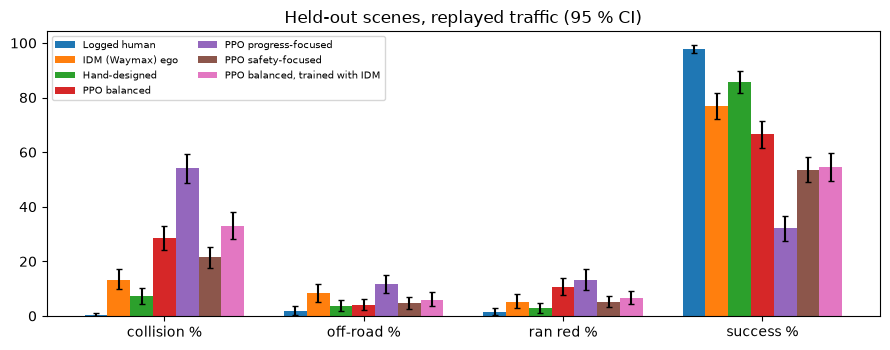

In [15]:
for sname in ("driving scenes", "waiting scenes"):
    display(Markdown(f"**Replayed traffic, {sname}**"))
    display(fmt(tables[("replay", sname)]))


def paired_tests(traffic, key_a, key_b="pure_pursuit"):
    from scipy.stats import binomtest
    A, B = load_method(traffic, key_a), load_method(traffic, key_b)
    a_coll = np.mean([d.collision.values for d in A], axis=0)
    b_coll = np.mean([d.collision.values for d in B], axis=0)
    a_bin, b_bin = a_coll >= 0.5, b_coll >= 0.5                 # majority over seeds
    n01, n10 = int((~a_bin & b_bin).sum()), int((a_bin & ~b_bin).sum())
    p = binomtest(n10, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    a_s = np.mean([d.success.values for d in A], axis=0)
    b_s = np.mean([d.success.values for d in B], axis=0)
    diff = a_s - b_s
    idx = resample_scenes(len(diff))
    lo, hi = np.percentile(diff[idx].mean(1), [2.5, 97.5])
    return dict(comparison=f"{LABELS[key_a]} vs {LABELS[key_b]}",
                **{"scenes only A collides": n10, "scenes only B collides": n01,
                   "McNemar p": "<0.001" if p < 0.001 else f"{p:.3f}", "success diff (pts)": round(100 * diff.mean(), 1),
                   "95% CI": f"[{100 * lo:.1f}, {100 * hi:.1f}]"})


h1 = pd.DataFrame([paired_tests("replay", k) for k in ("balanced", "progress", "safety", "idmtrained")])
h1.to_csv(os.path.join(RESULTS_DIR, "h1_paired_tests.csv"), index=False)
display(h1)

t = tables[("replay", "all scenes")]
fig, ax = plt.subplots(figsize=(9, 3.6))
cols = ["collision", "offroad", "ran_red", "success"]
w = 0.8 / len(t)
for i, (_, r) in enumerate(t.iterrows()):
    ax.bar(np.arange(len(cols)) + i * w, [r[c] for c in cols], w,
           yerr=[[r[c] - r[c + "_ci"][0] for c in cols], [r[c + "_ci"][1] - r[c] for c in cols]],
           capsize=2, label=r["method"])
ax.set_xticks(np.arange(len(cols)) + w * (len(t) - 1) / 2)
ax.set_xticklabels(["collision %", "off-road %", "ran red %", "success %"])
ax.legend(fontsize=7, ncol=2)
ax.set_title("Held-out scenes, replayed traffic (95 % CI)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "main_comparison.png"), dpi=130)
plt.show()

## 9. Experiment 2 (H2): replayed vs reactive traffic

Policies trained against replayed traffic are evaluated again with the other cars
driven by IDM, and a second set of policies trained with IDM traffic is evaluated both
ways. The logged human and the hand-designed controller show how much of any change
comes from the traffic model itself: the logged trajectory does not react, so it can
run into a car that now drives differently from the recording.

,method,collision % (replay eval),success % (replay eval),collision % (idm eval),success % (idm eval)
0,Logged human,0.3,97.9,6.6,92.0
1,Hand-designed,7.3,85.8,7.3,84.4
2,PPO balanced,28.6 ± 1.1,66.6 ± 0.9,26.3 ± 0.6,67.5 ± 1.1
3,PPO safety-focused,21.4 ± 1.3,53.5 ± 3.7,14.0 ± 1.3,53.7 ± 4.4
4,"PPO balanced, trained with IDM",33.0 ± 2.3,54.6 ± 3.4,23.8 ± 0.4,59.6 ± 3.8


,method,collision % (our IDM),collision % (Waymax IDM),success % (our IDM),success % (Waymax IDM),same collision outcome (% of scenes)
0,Logged human,6.6,14.6,92.0,83.7,84.4
1,Hand-designed,7.3,13.9,84.4,75.3,86.5
2,PPO balanced,27.1,30.9,66.7,61.5,83.0


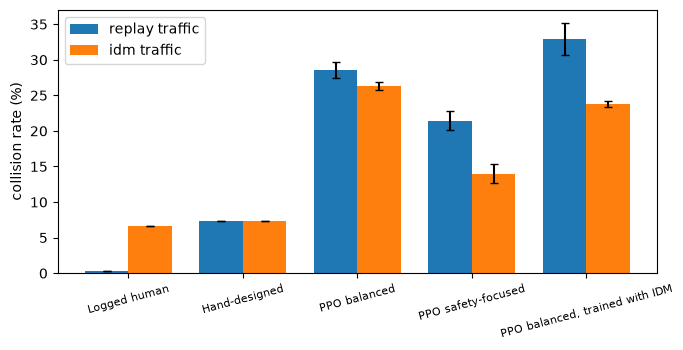

In [16]:
rows = []
for key in ("expert", "pure_pursuit", "balanced", "safety", "idmtrained"):
    r = {"method": LABELS[key]}
    for traffic in ("replay", "idm"):
        dfs = load_method(traffic, key)
        for m in ("collision", "success"):
            v = [100 * d[m].mean() for d in dfs]
            r[f"{m} % ({traffic} eval)"] = f"{np.mean(v):.1f}" + (f" ± {np.std(v):.1f}" if len(v) > 1 else "")
    rows.append(r)
h2 = pd.DataFrame(rows)
h2.to_csv(os.path.join(RESULTS_DIR, "h2_traffic.csv"), index=False)
display(h2)

# check our IDM traffic against Waymax's IDMRoutePolicy on the same scenes
check_rows = []
for method, run in (("expert", None), ("pure_pursuit", None), ("ppo", "balanced_s0")):
    ours = evaluate(method, "idm", run=run)
    theirs = evaluate(method, "waymax_idm", run=run)
    check_rows.append({"method": LABELS["balanced" if run else method],
                       "collision % (our IDM)": round(100 * ours.collision.mean(), 1),
                       "collision % (Waymax IDM)": round(100 * theirs.collision.mean(), 1),
                       "success % (our IDM)": round(100 * ours.success.mean(), 1),
                       "success % (Waymax IDM)": round(100 * theirs.success.mean(), 1),
                       "same collision outcome (% of scenes)":
                           round(100 * (ours.collision == theirs.collision).mean(), 1)})
idm_check = pd.DataFrame(check_rows)
idm_check.to_csv(os.path.join(RESULTS_DIR, "idm_check.csv"), index=False)
display(idm_check)

fig, ax = plt.subplots(figsize=(7, 3.6))
keys = ("expert", "pure_pursuit", "balanced", "safety", "idmtrained")
for j, traffic in enumerate(("replay", "idm")):
    vals = [np.mean([100 * d.collision.mean() for d in load_method(traffic, k)]) for k in keys]
    sds = [np.std([100 * d.collision.mean() for d in load_method(traffic, k)]) for k in keys]
    ax.bar(np.arange(len(keys)) + 0.38 * j, vals, 0.38, yerr=sds, capsize=3, label=f"{traffic} traffic")
ax.set_xticks(np.arange(len(keys)) + 0.19)
ax.set_xticklabels([LABELS[k] for k in keys], rotation=15, fontsize=8)
ax.set_ylabel("collision rate (%)")
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "traffic_models.png"), dpi=130)
plt.show()

## 10. Experiment 3 (H3): reward study

Three penalty scales (collision and off-road weight 10, 50 and 200), three seeds each.
Stop-and-wait shows up as *stalled* driving scenes (no failure but less than half the
logged distance covered), so we count those per setting as well as the progress in
waiting scenes, where stopping is the right behaviour.

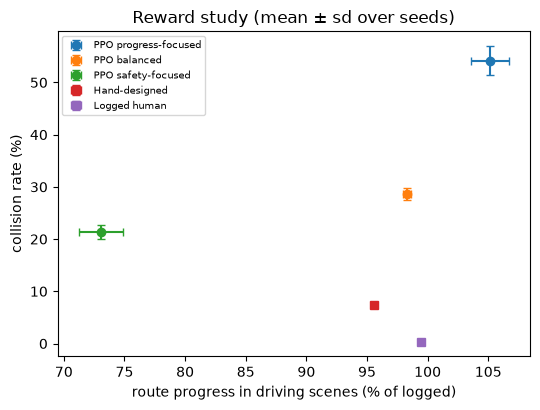

,method,seeds,collision %,collision sd,progress % (driving),stalled % (driving),per-seed stalled %
0,PPO progress-focused,3,54.2,2.8,105.1,0.0,"[0.0, 0.0, 0.0]"
1,PPO balanced,3,28.6,1.1,98.3,0.0,"[0.0, 0.0, 0.0]"
2,PPO safety-focused,3,21.4,1.3,73.1,14.5,"[17.3, 11.9, 14.3]"
3,Hand-designed,1,7.3,0.0,95.6,0.0,[0.0]
4,Logged human,1,0.3,0.0,99.4,0.0,[0.0]


In [17]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
study = []
for key, marker in (("progress", "o"), ("balanced", "o"), ("safety", "o"),
                    ("pure_pursuit", "s"), ("expert", "s")):
    dfs = load_method("replay", key)
    drv = [d[d.kind == "driving"] for d in dfs]
    prog = [100 * d.progress.mean() for d in drv]
    coll = [100 * d.collision.mean() for d in dfs]
    stall = [100 * (d.failure == "stalled").mean() for d in drv]
    ax.errorbar(np.mean(prog), np.mean(coll), xerr=np.std(prog), yerr=np.std(coll),
                fmt=marker, capsize=3, label=LABELS[key])
    study.append({"method": LABELS[key], "seeds": len(dfs),
                  "collision %": round(np.mean(coll), 1), "collision sd": round(np.std(coll), 1),
                  "progress % (driving)": round(np.mean(prog), 1),
                  "stalled % (driving)": round(np.mean(stall), 1),
                  "per-seed stalled %": [round(float(s), 1) for s in stall]})
ax.set_xlabel("route progress in driving scenes (% of logged)")
ax.set_ylabel("collision rate (%)")
ax.set_title("Reward study (mean ± sd over seeds)")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "reward_study.png"), dpi=130)
plt.show()
h3 = pd.DataFrame(study)
h3.to_csv(os.path.join(RESULTS_DIR, "h3_reward_study.csv"), index=False)
display(h3)

## 11. Experiment 4: failure analysis

Failure types per method, what was hit, and the ego's speed and gap at the moment of
failure. Then a few rendered episodes per failure type.

**Failure types, % of episodes (replayed traffic, pooled over seeds)**

,method,struck_from_behind,rear_end,collision_turning,collision_other,offroad_curve,offroad_straight,stalled
0,Logged human,0.3,0.0,0.0,0.0,0.0,1.7,0.0
1,IDM (Waymax) ego,1.4,4.5,1.4,5.9,1.0,6.9,0.0
2,Hand-designed,2.8,0.7,0.7,3.1,0.3,3.5,0.0
3,PPO balanced,1.5,13.2,4.7,9.1,0.0,4.2,0.0
4,PPO progress-focused,3.1,22.0,13.5,15.5,4.5,6.9,0.0
5,PPO safety-focused,6.6,4.5,3.6,6.7,0.7,3.9,8.4
6,"PPO balanced, trained with IDM",7.2,9.6,6.4,9.8,0.9,5.1,0.0


,method,collisions,hit a pedestrian/cyclist %,"speed at failure (m/s, median)","gap to nearest object at collision (m, median)",ran red %,failures in waiting scenes %
0,Logged human,1,100.0,0.0,3.4,1.4,3.3
1,IDM (Waymax) ego,38,2.6,6.7,4.3,5.2,21.7
2,Hand-designed,21,0.0,3.0,4.5,2.8,11.7
3,PPO balanced,247,5.7,5.2,4.6,10.5,52.2
4,PPO progress-focused,468,6.2,10.2,4.4,13.3,93.6
5,PPO safety-focused,185,3.8,3.7,4.6,5.2,25.0
6,"PPO balanced, trained with IDM",285,5.6,6.7,4.6,6.7,49.7


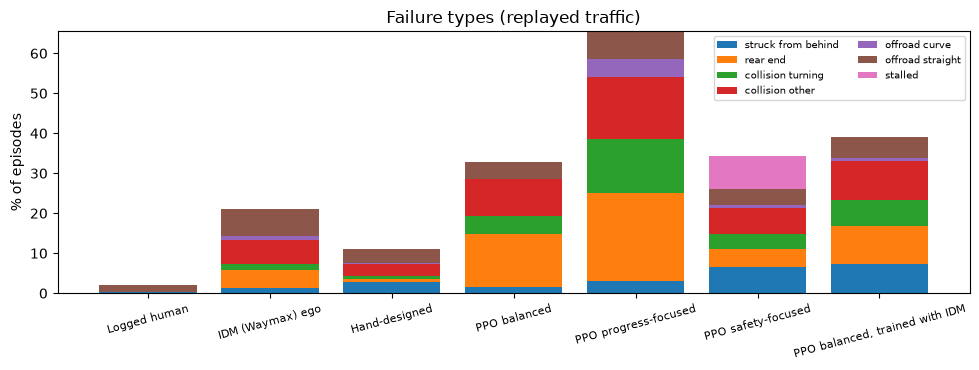

In [18]:
fail_rows, ctx_rows = [], []
FAILS = ["struck_from_behind", "rear_end", "collision_turning", "collision_other",
         "offroad_curve", "offroad_straight", "stalled"]
for key in ALL_KEYS:
    df = pd.concat(load_method("replay", key))
    counts = df.failure.value_counts(normalize=True)
    fail_rows.append({"method": LABELS[key], **{f: round(100 * counts.get(f, 0.0), 1) for f in FAILS}})
    coll = df[df.collision]
    ctx_rows.append({"method": LABELS[key], "collisions": len(coll),
                     "hit a pedestrian/cyclist %": round(100 * coll.hit_vru.mean(), 1) if len(coll) else 0,
                     "speed at failure (m/s, median)": round(df.fail_speed.median(), 1),
                     "gap to nearest object at collision (m, median)": round(coll.fail_gap.median(), 1),
                     "ran red %": round(100 * df.ran_red.mean(), 1),
                     "failures in waiting scenes %": round(100 * (df[df.kind == "waiting"].failure != "none").mean(), 1)})
fail_df, ctx_df = pd.DataFrame(fail_rows), pd.DataFrame(ctx_rows)
fail_df.to_csv(os.path.join(RESULTS_DIR, "failure_types.csv"), index=False)
ctx_df.to_csv(os.path.join(RESULTS_DIR, "failure_context.csv"), index=False)
display(Markdown("**Failure types, % of episodes (replayed traffic, pooled over seeds)**"))
display(fail_df)
display(ctx_df)

fig, ax = plt.subplots(figsize=(10, 3.8))
bottom = np.zeros(len(fail_df))
for f in FAILS:
    ax.bar(fail_df.method, fail_df[f], bottom=bottom, label=f.replace("_", " "))
    bottom += fail_df[f].values
ax.set_ylabel("% of episodes")
ax.set_title("Failure types (replayed traffic)")
ax.legend(fontsize=7, ncol=2)
plt.setp(ax.get_xticklabels(), rotation=15, fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "failure_types.png"), dpi=130)
plt.show()

best PPO setting by collision + off-road: PPO safety-focused


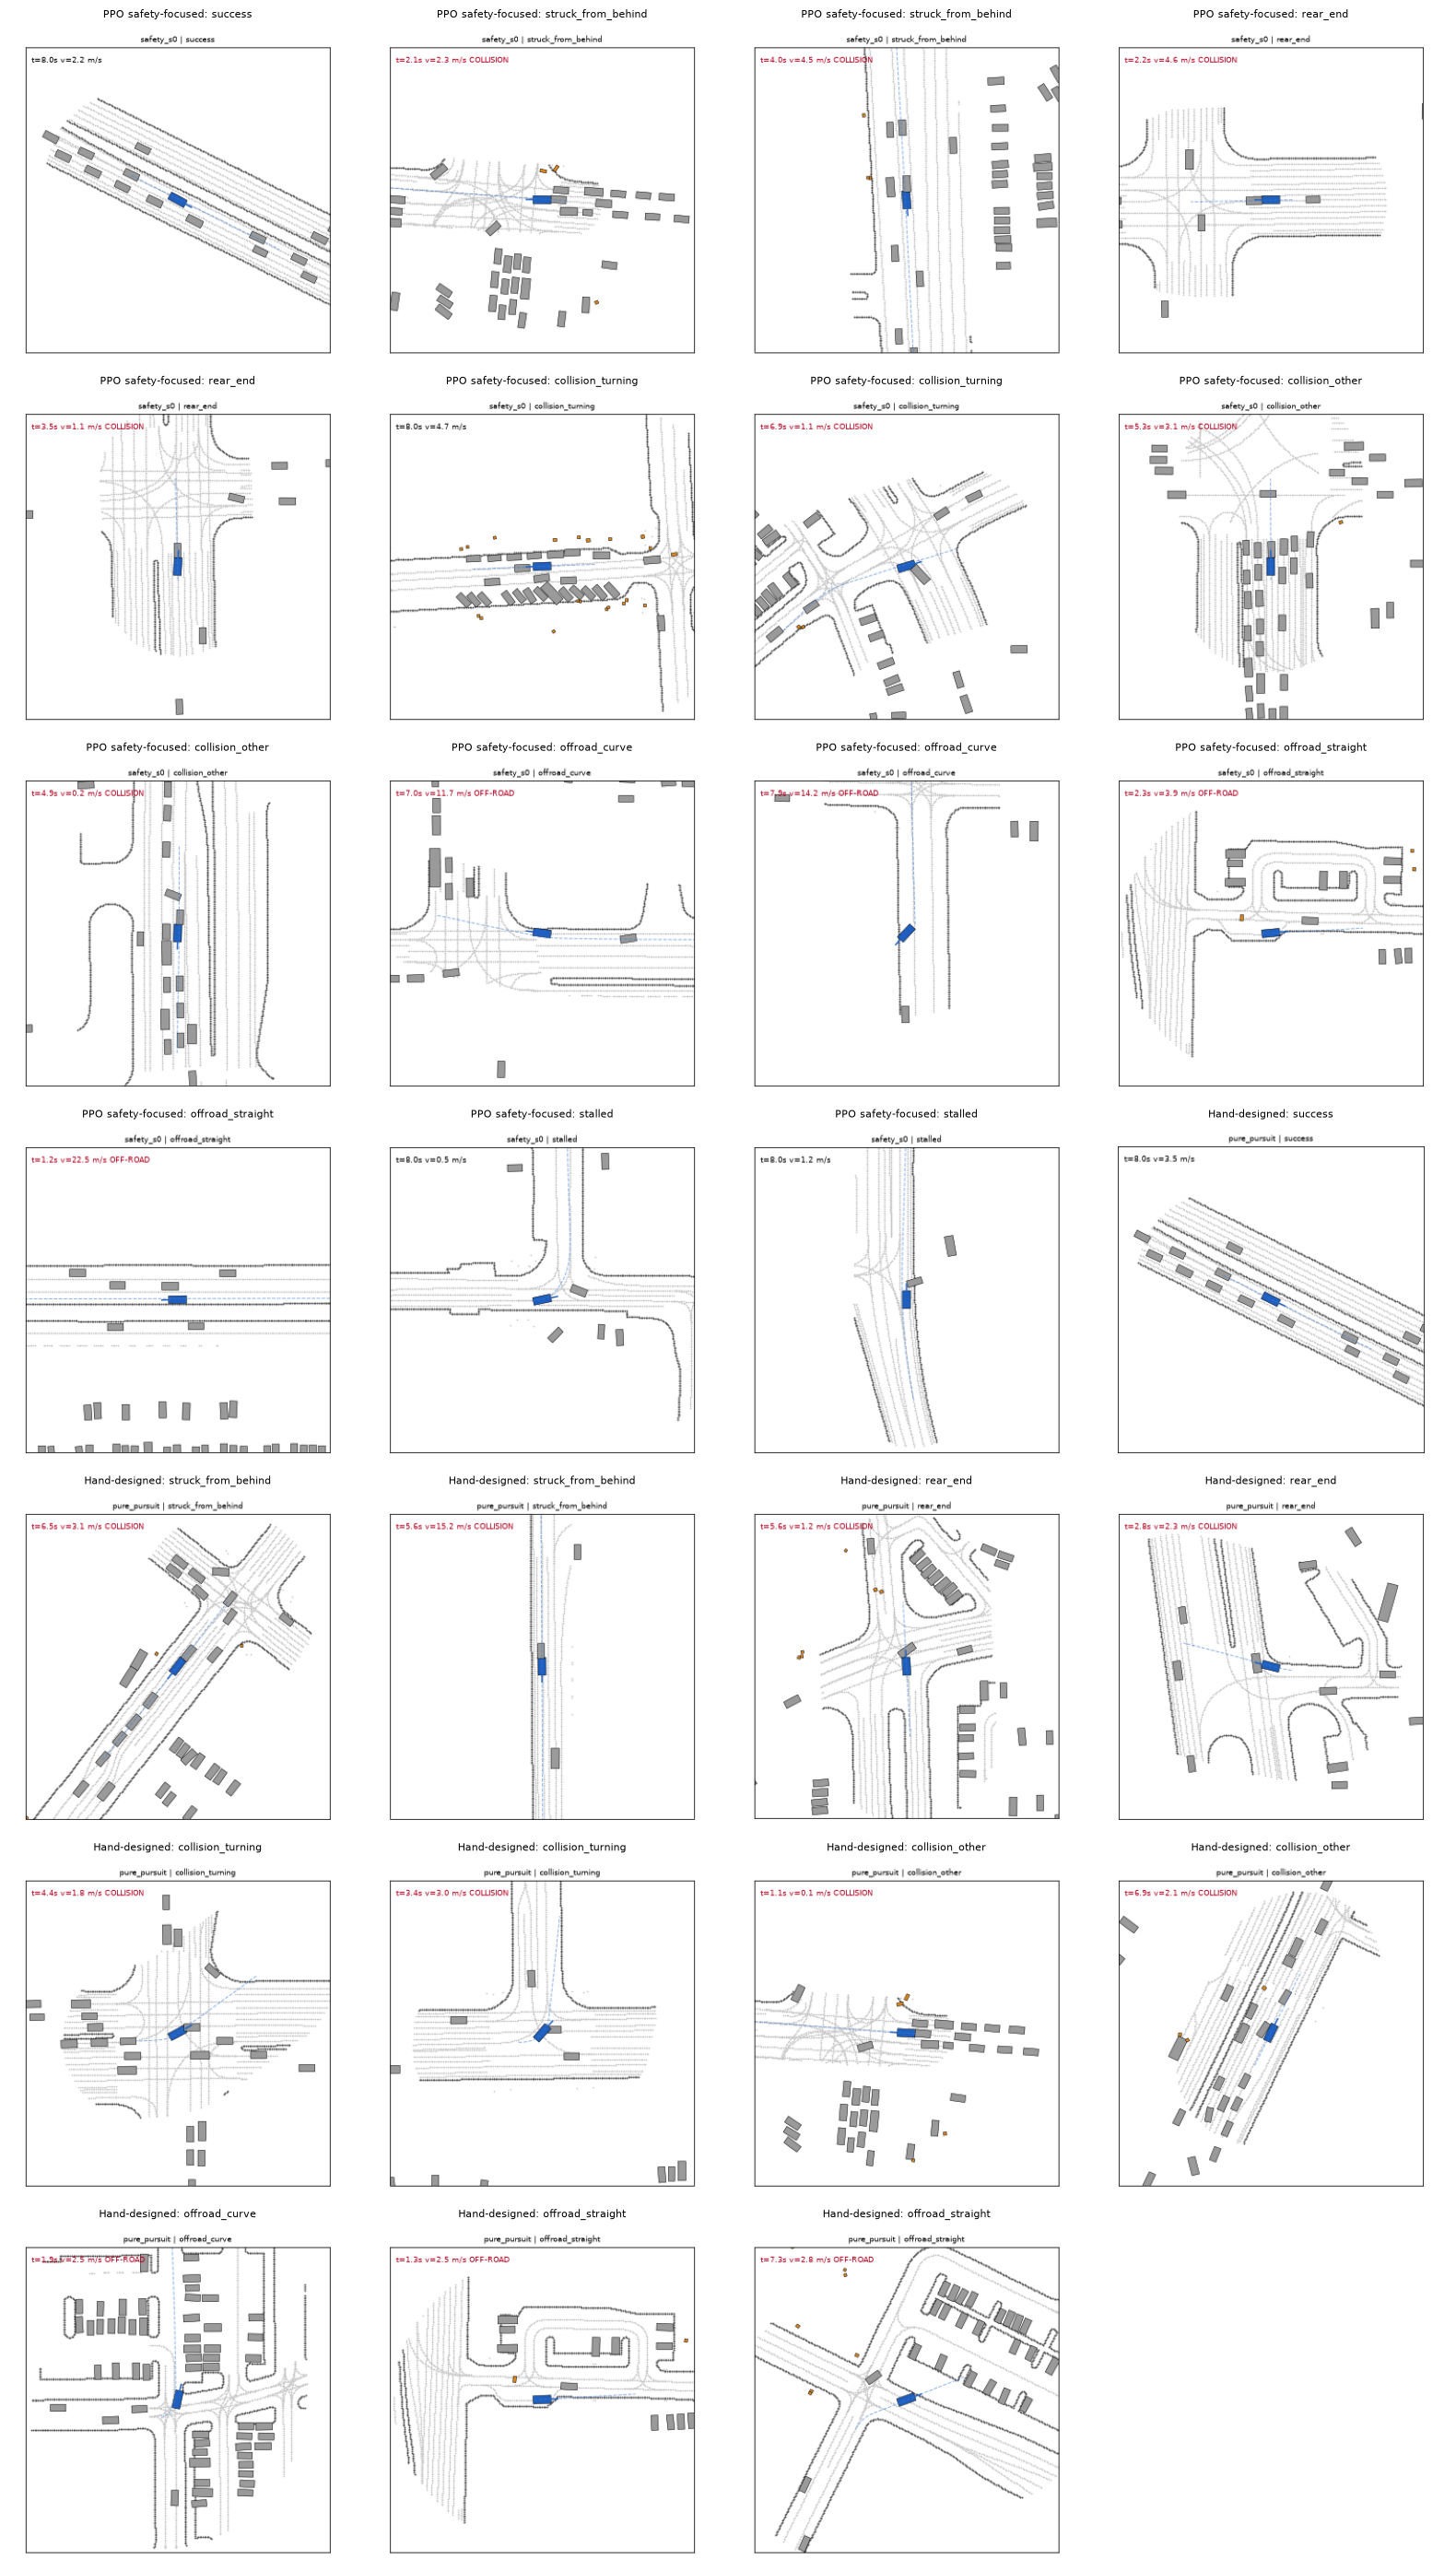

In [19]:
def draw_frame(sim, route, title, status, view=45.0, dpi=70):
    t = int(sim.timestep)
    traj = sim.sim_trajectory
    sdc = int(np.argmax(sim.object_metadata.is_sdc))
    ex, ey = float(traj.x[sdc, t]), float(traj.y[sdc, t])
    fig, ax = plt.subplots(figsize=(5, 5), dpi=dpi)
    rg = sim.roadgraph_points
    v = np.asarray(rg.valid)
    edge = v & np.isin(np.asarray(rg.types), ROAD_EDGE_TYPES)
    ax.scatter(rg.x[v & ~edge], rg.y[v & ~edge], s=0.5, c="#c8c8c8")
    ax.scatter(rg.x[edge], rg.y[edge], s=1.0, c="#555555")
    ax.plot(route[:, 0], route[:, 1], "--", lw=1, c="#3b7dd8", alpha=0.6)
    types = np.asarray(sim.object_metadata.object_types)
    for i in range(traj.x.shape[0]):
        if not traj.valid[i, t]:
            continue
        c, s_ = np.cos(traj.yaw[i, t]), np.sin(traj.yaw[i, t])
        L, W = traj.length[i, t], traj.width[i, t]
        box = np.array([[L / 2, W / 2], [L / 2, -W / 2], [-L / 2, -W / 2], [-L / 2, W / 2]])
        box = box @ np.array([[c, -s_], [s_, c]]).T + [traj.x[i, t], traj.y[i, t]]
        color = "#1f5fbf" if i == sdc else ("#e08a1e" if types[i] > 1 else "#9a9a9a")
        ax.add_patch(Polygon(box, closed=True, fc=color, ec="k", lw=0.5))
        if i == sdc:                        # short line out of the front bumper
            ax.plot([ex + c * L / 2, ex + c * (L / 2 + 2.0)], [ey + s_ * L / 2, ey + s_ * (L / 2 + 2.0)],
                    c="#1f5fbf", lw=1.5)
    ax.set_xlim(ex - view, ex + view)
    ax.set_ylim(ey - view, ey + view)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=8)
    ax.text(0.02, 0.97, status, transform=ax.transAxes, va="top", fontsize=8,
            color="#b00020" if ("COLLISION" in status or "OFF-ROAD" in status) else "k")
    fig.tight_layout()
    fig.canvas.draw()
    img = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
    plt.close(fig)
    return img


@functools.lru_cache(maxsize=None)
def episode_runner(method, run, env_kwargs=()):
    """Environment, jitted actor and jitted step for one method, built once."""
    dyn = "state" if method in ("expert", "idm_ego") else "bicycle"
    env = DrivingEnv(val_bank, ego_dynamics=dyn, **dict(env_kwargs))
    policy = load_policy(os.path.join(RUNS_DIR, run)) if run else None
    return env, jax.jit(make_actor(env, method, policy)), jax.jit(env.step_waymax)


def render_episode(method, run, idx, label, out_dir, env_kwargs=None, view=45.0):
    """Renders one held-out episode to an mp4 and returns its frames; the last frame is
    the step that ended the episode."""
    import mediapy
    env, act, step = episode_runner(method, run, tuple(sorted((env_kwargs or {}).items())))
    es = env.reset_idx(idx)
    obs = env.observe(es)
    route = np.asarray(val_bank["routes"]["route"][idx])[np.asarray(val_bank["routes"]["route_valid"][idx])]
    frames, status = [], ""
    for t in range(EPISODE_STEPS):
        es, obs, _, done, info = step(es, act(es, obs))
        if bool(info["collision"]):
            status = "COLLISION"
        elif bool(info["offroad"]):
            status = "OFF-ROAD"
        sim = jtu.tree_map(np.asarray, jax.device_get(es.sim))
        frames.append(draw_frame(sim, route, f"{run or method} | {label}",
                                 f"t={0.1 * (t + 1):.1f}s v={float(info['speed']):.1f} m/s {status}", view))
        if bool(done):
            break
    os.makedirs(out_dir, exist_ok=True)
    mediapy.write_video(os.path.join(out_dir, f"{label}_{idx}.mp4"), frames + [frames[-1]] * 10, fps=10)
    return frames


best_ppo = min(("balanced", "progress", "safety"),
               key=lambda k: np.mean([d.collision.mean() + d.offroad.mean() for d in load_method("replay", k)]))
print("best PPO setting by collision + off-road:", LABELS[best_ppo])
shown = []
for key, run in ((best_ppo, f"{best_ppo}_s0"), ("pure_pursuit", None)):
    df = pd.read_csv(os.path.join(RESULTS_DIR, "replay", f"{run or key}.csv"))
    picks = [(i, "success") for i in df.index[df.success][:1]]
    for f in FAILS:
        picks += [(i, f) for i in df.index[df.failure == f][:2]]
    for i, label in picks:
        img = render_episode("ppo" if run else key, run, int(i), label,
                             os.path.join(VIDEO_DIR, run or key))[-1]
        shown.append((f"{LABELS[key]}: {label}", img))

ncol = 4
nrow = int(np.ceil(len(shown) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 4 * nrow))
for ax in np.atleast_1d(axes).ravel():
    ax.axis("off")
for ax, (title, img) in zip(np.atleast_1d(axes).ravel(), shown):
    ax.imshow(img)
    ax.set_title(title, fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "failure_frames.png"), dpi=110)
plt.show()

### Checking the failure labels

The failure types above come from simple geometric rules, so we check them by eye. Up to
ten episodes per type are drawn at random from four methods (the three reward settings,
seed 0, and the hand-designed controller), rendered with a closer view, and laid out as
one sheet per type with the frame 1 s before, 0.5 s before and at the last step. The
sample is written to `results/classifier_check.csv`; after watching each episode we fill
in whether the label matches what happened (`agrees`) and a note when it does not.

In [20]:
CHECK_RUNS = (("ppo", "balanced_s0"), ("ppo", "progress_s0"), ("ppo", "safety_s0"), ("pure_pursuit", None))
CHECK_PER_TYPE = 10 if not SMOKE else 1
check_path = os.path.join(RESULTS_DIR, "classifier_check.csv")
check_dir = os.path.join(VIDEO_DIR, "classifier_check")

if not os.path.exists(check_path):
    pool = []
    for method, run in CHECK_RUNS:
        df = pd.read_csv(os.path.join(RESULTS_DIR, "replay", f"{run or method}.csv"))
        pool.append(pd.DataFrame({"method": method, "run": run or method, "scene": df.index,
                                  "label": df.failure}))
    pool = pd.concat(pool, ignore_index=True)
    sample = pd.concat([g.sample(min(CHECK_PER_TYPE, len(g)), random_state=0)
                        for _, g in pool[pool.label.isin(FAILS)].groupby("label")])
    sample = sample.sort_values(["label", "run", "scene"]).assign(agrees="", note="")
    sample.to_csv(check_path, index=False)

checked = pd.read_csv(check_path, keep_default_na=False)
for label, g in checked.groupby("label"):
    sheet = os.path.join(check_dir, f"{label}.png")
    if os.path.exists(sheet):
        continue
    fig, axes = plt.subplots(len(g), 3, figsize=(10.5, 3.5 * len(g)), squeeze=False)
    for row, e in zip(axes, g.itertuples()):
        frames = render_episode(e.method, e.run if e.method == "ppo" else None, int(e.scene), label,
                                os.path.join(check_dir, e.run), view=25.0)
        for ax, k, when in zip(row, (11, 6, 1), ("1 s before", "0.5 s before", "last step")):
            ax.imshow(frames[-min(k, len(frames))])
            ax.set_title(f"{e.run}, scene {e.scene}: {when}", fontsize=7)
            ax.axis("off")
    fig.tight_layout()
    fig.savefig(sheet, dpi=100)
    plt.close(fig)

seen = checked[checked.agrees != ""]
if len(seen):
    tally = seen.groupby("label").agrees.agg(checked="size", agree=lambda a: int((a == "yes").sum()))
    tally.loc["all"] = tally.sum()
    display(tally)
    display(seen[seen.agrees != "yes"][["run", "scene", "label", "note"]])
else:
    print(f"{len(checked)} episodes sampled and rendered to {check_dir}; 'agrees' not filled in yet")

,checked,agree
label,,
collision_other,10,7
collision_turning,10,3
offroad_curve,10,1
offroad_straight,10,9
rear_end,10,8
stalled,10,6
struck_from_behind,10,10
all,70,44


,run,scene,label,note
1,balanced_s0,190,collision_other,rear-end: runs into the car directly ahead in ...
3,progress_s0,97,collision_other,rear-end: runs into the car directly ahead in ...
4,progress_s0,120,collision_other,rear-end: runs into the car directly ahead in ...
10,progress_s0,64,collision_turning,"straight road, runs into the car ahead (rear-end)"
11,progress_s0,84,collision_turning,going straight through an intersection
12,progress_s0,87,collision_turning,"straight road, runs into the car ahead (rear-end)"
13,progress_s0,192,collision_turning,"straight road, runs into the car ahead (rear-end)"
14,progress_s0,211,collision_turning,"going straight, hits a vehicle crossing the in..."
15,progress_s0,239,collision_turning,"straight road, runs into the car ahead (rear-end)"
16,progress_s0,287,collision_turning,"straight road, runs into the queue ahead (rear..."


**What the check showed.** The table above counts, per type, how many sampled episodes
we looked at and in how many the label matched. Three labels are reliable (*struck from
behind*, *off-road on a straight*, *rear-end*). *Collision while turning* mostly is not:
the rule also fires on the ego's own curvature, and the policies' constant small steering
corrections push that over the threshold on straight roads, so most of these episodes
are in fact rear-ends or collisions with crossing traffic. *Off-road on a curve* is
dominated by one policy driving past the end of its logged path. Several *stalled*
episodes are slow rather than stopped. The notes in `results/classifier_check.csv` say
what we saw in each disagreement.

Because of the off-road cases, the next table splits every off-road event by where it
happened: in the first two steps (the ego starts outside the mapped road), after the ego
has passed the end of the logged path (on the straight 30 m extension of the route,
which need not stay on the road), or within the logged path.

In [21]:
def offroad_split(df):
    off = df.offroad
    start = off & (df.steps <= 2)
    past = off & ~start & (df.covered_m > df.logged_m + 2.0)
    return {"off-road %": round(100 * off.mean(), 1),
            "at the start %": round(100 * start.mean(), 1),
            "past the logged path %": round(100 * past.mean(), 1),
            "within the logged path %": round(100 * (off & ~start & ~past).mean(), 1)}


off_ctx = pd.DataFrame([{"method": LABELS[key], **offroad_split(pd.concat(load_method("replay", key)))}
                        for key in ALL_KEYS])
off_ctx.to_csv(os.path.join(RESULTS_DIR, "offroad_context.csv"), index=False)
display(Markdown("**Where off-road events happen, % of episodes (replayed traffic)**"))
display(off_ctx)

**Where off-road events happen, % of episodes (replayed traffic)**

,method,off-road %,at the start %,past the logged path %,within the logged path %
0,Logged human,1.7,1.4,0.0,0.3
1,IDM (Waymax) ego,8.3,1.4,6.6,0.3
2,Hand-designed,3.8,1.4,1.4,1.0
3,PPO balanced,4.2,1.4,1.5,1.3
4,PPO progress-focused,11.7,1.4,8.4,1.9
5,PPO safety-focused,4.6,1.4,1.0,2.2
6,"PPO balanced, trained with IDM",6.0,1.4,1.4,3.2


## 12. Smoothness

In [22]:
t = tables[("replay", "all scenes")]
smooth = pd.DataFrame({"method": t.method,
                       "mean |jerk| (m/s³)": [f"{v:.2f} ± {s:.2f}" if not np.isnan(s) else f"{v:.2f}"
                                              for v, s in zip(t.mean_abs_jerk, t.mean_abs_jerk_sd)],
                       "mean |Δκ| (1/m per step)": [f"{v:.4f}" for v in t.mean_abs_dkappa],
                       "return (balanced reward)": [f"{v:.1f}" for v in t.ep_return]})
smooth.to_csv(os.path.join(RESULTS_DIR, "smoothness.csv"), index=False)
display(smooth)

,method,mean |jerk| (m/s³),mean |Δκ| (1/m per step),return (balanced reward)
0,Logged human,1.29,0.0006,66.2
1,IDM (Waymax) ego,2.06,0.0029,55.5
2,Hand-designed,1.84,0.0003,58.2
3,PPO balanced,3.61 ± 0.37,0.0073,43.5
4,PPO progress-focused,3.48 ± 0.54,0.0106,16.9
5,PPO safety-focused,6.75 ± 1.57,0.0081,30.9
6,"PPO balanced, trained with IDM",3.22 ± 0.12,0.0081,34.1


## 13. Stretch goals

**(1) Behaviour cloning and BC → PPO.** Expert actions are recovered from the logs
with the bicycle model's inverse dynamics (`InvertibleBicycleModel.inverse`). The
actor is trained to regress them from the same observation; we compare BC alone,
PPO from scratch and PPO initialised from BC (balanced reward, same budget).

**(2) Richer observation.** K = 10 nearest objects plus the 16 nearest road-edge points
in the ego frame, for denser traffic.

**(3) Harder slice.** PPO trained only on intersection scenes (the ego turns by more
than 30° or crosses a signal's stop line during the log: 100 of the 478 training
scenes), compared on the 45 held-out intersection scenes with the policy trained on
all scenes.

Each stretch setting uses three seeds, like the main runs.

In [23]:
def collect_bc_data(env):
    @jax.jit
    def run(idx):
        es = jax.vmap(env.reset_idx)(idx)

        def body(es, _):
            a = jax.vmap(env.expert_bicycle_action)(es)
            obs = jax.vmap(env.observe)(es)
            es2 = jax.vmap(env.step)(es, a)[0]
            return es2, (obs, a)

        _, (obs, act) = jax.lax.scan(body, es, None, EPISODE_STEPS)
        return obs.reshape(-1, obs.shape[-1]), act.reshape(-1, 2)

    xs, ys = [], []
    for start in range(0, env.num_scenarios, 48):
        idx = np.arange(start, min(start + 48, env.num_scenarios))
        o, a = jax.device_get(run(jnp.asarray(idx)))
        xs.append(np.asarray(o))
        ys.append(np.asarray(a))
    return np.concatenate(xs), np.concatenate(ys)


bc_dir = os.path.join(RUNS_DIR, "bc")
env_bc = DrivingEnv(train_bank)
if not os.path.exists(os.path.join(bc_dir, "checkpoint.pkl")):
    X, Y = collect_bc_data(env_bc)
    print(f"behaviour cloning data: {len(X)} (observation, action) pairs; "
          f"{100 * (np.abs(Y) > 1).any(1).mean():.1f}% of expert actions fall outside the "
          f"bicycle bounds and are clipped")
    Y = np.clip(Y, -1, 1)
    obs_norm_bc = ObsNorm.create(env_bc.obs_dim).update(jnp.asarray(X))
    net = ActorCritic(256, -1.6)
    params = net.init(jax.random.PRNGKey(0), jnp.zeros(env_bc.obs_dim))
    tx = optax.adam(1e-3)
    opt = tx.init(params)

    @jax.jit
    def bc_step(params, opt, xb, yb):
        def loss(p):
            return ((net.apply(p, obs_norm_bc(xb))[0] - yb) ** 2).mean()
        lval, g = jax.value_and_grad(loss)(params)
        upd, opt = tx.update(g, opt)
        return optax.apply_updates(params, upd), opt, lval

    rng = np.random.default_rng(0)
    for ep in range(30 if not SMOKE else 2):
        perm = rng.permutation(len(X))
        losses = []
        for b in range(0, len(X), 512):
            j = perm[b:b + 512]
            params, opt, lval = bc_step(params, opt, jnp.asarray(X[j]), jnp.asarray(Y[j]))
            losses.append(float(lval))
        if ep % 10 == 9:
            print(f"  BC epoch {ep + 1}: mse {np.mean(losses):.4f}")
    os.makedirs(bc_dir, exist_ok=True)
    with open(os.path.join(bc_dir, "checkpoint.pkl"), "wb") as f:
        pickle.dump(dict(params=jax.device_get(params), obs_norm=jax.device_get(obs_norm_bc),
                         opt_state=None, update=0, config=dataclasses.asdict(PPOConfig())), f)

bc_ck = load_checkpoint(os.path.join(bc_dir, "checkpoint.pkl"))
on = bc_ck["obs_norm"]
bc_obs_norm = ObsNorm(jnp.asarray(on.mean), jnp.asarray(on.var), jnp.asarray(on.count))
for seed in SEEDS:
    train_ppo(env_bc, PPOConfig(), seed, os.path.join(RUNS_DIR, f"bcppo_s{seed}"),
              init_params=bc_ck["params"], init_obs_norm=bc_obs_norm)
    env_rich = DrivingEnv(train_bank, k_neighbors=10, road_points=16)
    train_ppo(env_rich, PPOConfig(), seed, os.path.join(RUNS_DIR, f"rich_s{seed}"))

hard_idx = np.flatnonzero(train_bank["meta"].intersection.values)
print(f"intersection slice: {len(hard_idx)} training scenes, "
      f"{int(val_bank['meta'].intersection.sum())} held-out scenes")
env_hard = DrivingEnv(subset_bank(train_bank, hard_idx))
for seed in SEEDS:
    train_ppo(env_hard, PPOConfig(), seed, os.path.join(RUNS_DIR, f"hardslice_s{seed}"))

for traffic in ("replay", "idm"):
    evaluate("ppo", traffic, run="bc")
    for seed in SEEDS:
        evaluate("ppo", traffic, run=f"bcppo_s{seed}")
        evaluate("ppo", traffic, run=f"rich_s{seed}", env_kwargs=dict(k_neighbors=10, road_points=16))
        evaluate("ppo", traffic, run=f"hardslice_s{seed}")

STRETCH_KEYS = ["pure_pursuit", "bc", "balanced", "bcppo", "rich", "hardslice"]
stretch = {}
for sname, fn in (("all scenes", None), ("driving scenes", SLICES["driving scenes"]),
                  ("turning scenes", SLICES["turning scenes"]),
                  ("intersection scenes", SLICES["intersection scenes"])):
    stretch[sname] = summary("replay", STRETCH_KEYS, fn)
    display(Markdown(f"**Stretch goals, replayed traffic, {sname}**"))
    display(fmt(stretch[sname]))
stretch_idm = summary("idm", STRETCH_KEYS)
display(Markdown("**Stretch goals, reactive IDM traffic, all scenes**"))
display(fmt(stretch_idm))
with open(os.path.join(RESULTS_DIR, "tables.md"), "a") as f:
    for sname, t in stretch.items():
        f.write(f"\n### stretch goals, replay traffic, {sname}\n\n" + fmt(t).to_markdown(index=False) + "\n")
    f.write("\n### stretch goals, idm traffic, all scenes\n\n" + fmt(stretch_idm).to_markdown(index=False) + "\n")

rows = []
for key in STRETCH_KEYS:
    df = pd.concat(load_method("replay", key))
    counts = df.failure.value_counts(normalize=True)
    drv = df[df.kind == "driving"]
    rows.append({"method": LABELS[key], **{f: round(100 * counts.get(f, 0.0), 1) for f in FAILS},
                 "stalled % (driving)": round(100 * (drv.failure == "stalled").mean(), 1),
                 **offroad_split(df)})
stretch_fail = pd.DataFrame(rows)
stretch_fail.to_csv(os.path.join(RESULTS_DIR, "stretch_failures.csv"), index=False)
display(Markdown("**Failure types of the stretch runs and where they leave the road, % of episodes (replayed traffic)**"))
display(stretch_fail)

./runs/bcppo_s0: already trained (488 updates)


./runs/rich_s0: already trained (488 updates)
./runs/bcppo_s1: already trained (488 updates)


./runs/rich_s1: already trained (488 updates)
./runs/bcppo_s2: already trained (488 updates)


./runs/rich_s2: already trained (488 updates)
intersection slice: 100 training scenes, 45 held-out scenes


./runs/hardslice_s0: already trained (488 updates)


./runs/hardslice_s1: already trained (488 updates)
./runs/hardslice_s2: already trained (488 updates)


... (8 outputs left out)

**Stretch goals, reactive IDM traffic, all scenes**

,method,seeds,scenes,collision %,offroad %,ran_red %,progress %,success %
0,Hand-designed,1,288,"7.3 [4.5, 10.4]","2.8 [1.0, 4.9]","2.8 [1.0, 4.9]","73.7 [69.1, 78.4]","84.4 [80.2, 88.2]"
1,Behaviour cloning,1,288,"30.9 [25.7, 36.1]","44.8 [39.2, 51.0]","12.5 [9.0, 16.3]","44.9 [40.7, 49.2]","17.4 [13.2, 21.9]"
2,PPO balanced,3,288,"26.3 ± 0.6 [21.9, 30.6]","3.9 ± 0.3 [2.1, 5.9]","10.6 ± 2.0 [7.8, 13.8]","86.0 ± 1.8 [81.9, 90.1]","67.5 ± 1.1 [62.6, 72.2]"
3,BC → PPO,3,288,"27.7 ± 1.9 [23.3, 32.2]","6.0 ± 0.4 [3.6, 8.6]","8.2 ± 0.4 [5.6, 11.1]","85.6 ± 2.4 [81.0, 90.3]","64.0 ± 2.8 [59.0, 68.8]"
4,"PPO, K=10 + road edges",3,288,"28.7 ± 4.0 [24.5, 32.9]","5.9 ± 1.5 [3.6, 8.2]","10.2 ± 0.7 [7.2, 13.4]","83.5 ± 3.7 [79.1, 88.1]","59.3 ± 4.3 [54.9, 63.8]"
5,PPO trained on intersections,3,288,"32.1 ± 0.7 [27.2, 36.9]","9.5 ± 0.9 [6.7, 12.6]","13.8 ± 0.2 [10.1, 17.7]","87.0 ± 0.6 [82.6, 91.4]","57.2 ± 1.4 [52.2, 62.4]"


**Failure types of the stretch runs and where they leave the road, % of episodes (replayed traffic)**

,method,struck_from_behind,rear_end,collision_turning,collision_other,offroad_curve,offroad_straight,stalled,stalled % (driving),off-road %,at the start %,past the logged path %,within the logged path %
0,Hand-designed,2.8,0.7,0.7,3.1,0.3,3.5,0.0,0.0,3.8,1.4,1.4,1.0
1,Behaviour cloning,2.8,4.9,27.1,3.8,4.2,38.2,1.4,2.4,42.7,1.4,3.8,37.5
2,PPO balanced,1.5,13.2,4.7,9.1,0.0,4.2,0.0,0.0,4.2,1.4,1.5,1.3
3,BC → PPO,1.4,12.0,6.2,8.7,0.2,4.9,0.0,0.0,5.1,1.4,1.5,2.2
4,"PPO, K=10 + road edges",3.5,10.8,12.0,8.2,0.5,5.3,0.6,1.0,5.9,1.4,2.5,2.0
5,PPO trained on intersections,1.2,12.4,9.7,10.2,0.5,9.5,0.1,0.2,10.0,1.6,2.1,6.2


## 14. Improving the policy

Sections 8 to 11 point to three weaknesses of the balanced policy: it does not wait
when the human waited (it creeps into stopped queues and through red lights), its most
common failure is running into the vehicle ahead, and it steers with many small
corrections. The hand-designed controller avoids the first two because it explicitly
tracks the gap to whatever is ahead in its lane, including a red stop line. We give
the policy the same information and make the reward say what the evaluation measures:

- **Lead-vehicle features (3 values, 53 in total).** Gap, closing speed and time to collision to the
  nearest object ahead within ±2 m laterally, or to the stop line of a red light on the
  route, whichever is closer.
- **Time-to-collision penalty.** Up to 2 per step when the time to collision with that
  object drops below 2 s while moving (`w_ttc`).
- **Red-light penalty.** 50 for crossing an on-route stop line on red (`w_red`), the same
  weight as a collision.
- **Smoother control.** The control weight goes from 0.05 to 0.1.

Everything else is the balanced setting: same network, same PPO settings, the same
2M steps and three seeds.

The first version measured "ahead" in the ego's own frame (the 2 m band follows the
car's heading). Its failure table showed fewer collisions but more off-road exits on
straight roads, which suggests a loophole: steering out of the lane makes the stopped
car ahead leave the band, which removes the time-to-collision penalty. The second
version measures gap and closing speed along the route instead, so swerving no longer
hides the vehicle ahead.

Both versions turned out to lose most of their gain when the other cars react
(section 15), so a third version trains the first one on *mixed traffic*: each training
episode is replayed or reactive with equal probability, decided at reset. Nothing else
differs from the first version.

All three versions are reported. None was tuned on the held-out numbers beyond these
changes, and they are kept apart from the hypothesis tests above, which stay as
designed.

In [24]:
IMPROVED = {"improved": dict(lead_features=True),
            "improved2": dict(lead_features=True, lead_frame="route"),
            "improved3": dict(lead_features=True)}
TRAIN_TRAFFIC = {"improved3": "mixed"}      # the others train on replayed traffic
for name, kw in IMPROVED.items():
    for seed in SEEDS:
        env_imp = DrivingEnv(train_bank, REWARD_PRESETS["improved"],
                             traffic=TRAIN_TRAFFIC.get(name, "replay"), **kw)
        train_ppo(env_imp, PPOConfig(), seed, os.path.join(RUNS_DIR, f"{name}_s{seed}"))
    for traffic in ("replay", "idm"):
        for seed in SEEDS:
            evaluate("ppo", traffic, run=f"{name}_s{seed}", env_kwargs=kw)

imp_keys = ["expert", "pure_pursuit", "balanced", "safety", "improved", "improved2", "improved3"]
imp_tables = {(t, sn): summary(t, imp_keys, fn) for t in ("replay", "idm") for sn, fn in SLICES.items()}
with open(os.path.join(RESULTS_DIR, "tables.md"), "a") as f:
    for (t, sn), tab in imp_tables.items():
        f.write(f"\n### improved policy, {t} traffic, {sn}\n\n" + fmt(tab).to_markdown(index=False) + "\n")
for sn in ("all scenes", "driving scenes", "waiting scenes", "intersection scenes"):
    display(Markdown(f"**Replayed traffic, {sn}**"))
    display(fmt(imp_tables[("replay", sn)]))
display(Markdown("**Reactive IDM traffic, all scenes**"))
display(fmt(imp_tables[("idm", "all scenes")]))

pairs = ([(t, a, b) for t in ("replay", "idm") for a in ("improved", "improved2", "improved3")
          for b in ("pure_pursuit", "balanced")]
         + [("replay", "improved2", "improved"), ("replay", "improved3", "improved"),
            ("idm", "improved3", "improved")])
imp_tests = pd.DataFrame([paired_tests(t, a, b) for t, a, b in pairs])
imp_tests.insert(0, "traffic", [t for t, _, _ in pairs])
imp_tests.to_csv(os.path.join(RESULTS_DIR, "improved_paired_tests.csv"), index=False)
display(imp_tests)

./runs/improved_s0: already trained (488 updates)


./runs/improved_s1: already trained (488 updates)


./runs/improved_s2: already trained (488 updates)


./runs/improved2_s0: already trained (488 updates)


./runs/improved2_s1: already trained (488 updates)
./runs/improved2_s2: already trained (488 updates)


  improved3_s0 [50/488] ret=-1.2 coll=0.140 off=0.123 prog=0.60 (34s)


... (42 outputs left out)

,method,seeds,scenes,collision %,offroad %,ran_red %,progress %,success %
0,Logged human,1,45,"0.0 [0.0, 0.0]","2.2 [0.0, 6.7]","8.9 [2.2, 17.8]","94.6 [89.7, 98.3]","97.8 [93.3, 100.0]"
1,Hand-designed,1,45,"8.9 [2.2, 17.8]","8.9 [2.2, 17.8]","4.4 [0.0, 11.1]","90.3 [81.8, 97.9]","75.6 [62.2, 88.9]"
2,PPO balanced,3,45,"18.5 ± 2.8 [9.6, 28.1]","3.7 ± 1.0 [0.0, 9.6]","7.4 ± 1.0 [0.7, 15.6]","97.5 ± 1.8 [86.9, 107.6]","76.3 ± 2.1 [65.2, 85.9]"
3,PPO safety-focused,3,45,"24.4 ± 0.0 [14.8, 35.6]","3.0 ± 1.0 [0.0, 8.1]","4.4 ± 1.8 [0.0, 10.4]","65.3 ± 3.4 [54.0, 76.3]","38.5 ± 5.2 [27.4, 49.6]"
4,PPO + lead/TTC/red terms,3,45,"8.1 ± 2.8 [2.2, 16.3]","11.9 ± 1.0 [5.9, 18.5]","5.2 ± 1.0 [0.0, 11.9]","108.3 ± 5.2 [99.0, 117.3]","74.8 ± 4.2 [64.4, 84.4]"
5,"PPO + lead/TTC/red terms, route frame",3,45,"11.9 ± 2.1 [4.4, 20.7]","11.1 ± 0.0 [4.4, 19.3]","4.4 ± 0.0 [0.0, 11.1]","108.1 ± 2.1 [96.6, 119.2]","74.1 ± 2.8 [63.0, 84.4]"
6,"PPO + lead/TTC/red terms, mixed traffic",3,45,"7.4 ± 2.8 [2.2, 14.8]","12.6 ± 4.2 [5.9, 20.7]","4.4 ± 1.8 [0.0, 10.4]","111.5 ± 1.2 [100.1, 122.6]","71.9 ± 3.8 [60.7, 81.5]"


**Reactive IDM traffic, all scenes**

,method,seeds,scenes,collision %,offroad %,ran_red %,progress %,success %
0,Logged human,1,288,"6.6 [4.2, 9.4]","1.4 [0.3, 2.8]","1.0 [0.0, 2.4]","64.5 [59.7, 69.2]","92.0 [88.9, 94.8]"
1,Hand-designed,1,288,"7.3 [4.5, 10.4]","2.8 [1.0, 4.9]","2.8 [1.0, 4.9]","73.7 [69.1, 78.4]","84.4 [80.2, 88.2]"
2,PPO balanced,3,288,"26.3 ± 0.6 [21.9, 30.6]","3.9 ± 0.3 [2.1, 5.9]","10.6 ± 2.0 [7.8, 13.8]","86.0 ± 1.8 [81.9, 90.1]","67.5 ± 1.1 [62.6, 72.2]"
3,PPO safety-focused,3,288,"14.0 ± 1.3 [10.8, 17.4]","5.0 ± 1.9 [3.0, 7.1]","5.7 ± 0.6 [3.5, 8.0]","62.8 ± 1.1 [58.6, 67.2]","53.7 ± 4.4 [49.2, 58.4]"
4,PPO + lead/TTC/red terms,3,288,"21.8 ± 1.1 [17.4, 26.2]","7.5 ± 1.4 [5.1, 10.1]","3.0 ± 0.4 [1.4, 5.0]","90.4 ± 2.9 [84.5, 96.5]","68.4 ± 2.0 [63.7, 73.1]"
5,"PPO + lead/TTC/red terms, route frame",3,288,"19.7 ± 1.3 [15.6, 24.0]","7.2 ± 1.1 [4.9, 9.6]","3.0 ± 0.2 [1.4, 5.1]","89.4 ± 1.1 [83.7, 95.2]","70.3 ± 2.6 [65.6, 74.9]"
6,"PPO + lead/TTC/red terms, mixed traffic",3,288,"17.0 ± 0.5 [13.2, 20.8]","7.5 ± 0.9 [5.1, 10.1]","2.7 ± 0.2 [1.0, 4.6]","88.5 ± 0.9 [82.6, 94.5]","71.8 ± 0.7 [67.4, 76.0]"


,traffic,comparison,scenes only A collides,scenes only B collides,McNemar p,success diff (pts),95% CI
0,replay,PPO + lead/TTC/red terms vs Hand-designed,13,13,1.000,-3.9,"[-8.2, 0.2]"
1,replay,PPO + lead/TTC/red terms vs PPO balanced,7,66,<0.001,15.3,"[10.3, 20.3]"
2,replay,"PPO + lead/TTC/red terms, route frame vs Hand-...",16,10,0.327,-5.1,"[-9.4, -0.9]"
3,replay,"PPO + lead/TTC/red terms, route frame vs PPO b...",8,61,<0.001,14.1,"[8.9, 19.1]"
4,replay,"PPO + lead/TTC/red terms, mixed traffic vs Han...",19,11,0.200,-7.2,"[-11.6, -3.0]"
5,replay,"PPO + lead/TTC/red terms, mixed traffic vs PPO...",12,63,<0.001,12.0,"[6.9, 17.0]"
6,idm,PPO + lead/TTC/red terms vs Hand-designed,44,8,<0.001,-16.0,"[-21.3, -10.5]"
7,idm,PPO + lead/TTC/red terms vs PPO balanced,12,32,0.004,0.9,"[-2.9, 4.7]"
8,idm,"PPO + lead/TTC/red terms, route frame vs Hand-...",47,13,<0.001,-14.1,"[-19.6, -8.4]"
9,idm,"PPO + lead/TTC/red terms, route frame vs PPO b...",11,33,0.001,2.8,"[-1.4, 6.7]"


,method,struck_from_behind,rear_end,collision_turning,collision_other,offroad_curve,offroad_straight,stalled,ran red %,mean |jerk|,mean |Δκ|,off-road %,at the start %,past the logged path %,within the logged path %
0,Hand-designed,2.8,0.7,0.7,3.1,0.3,3.5,0.0,2.8,1.84,0.0003,3.8,1.4,1.4,1.0
1,PPO balanced,1.5,13.2,4.7,9.1,0.0,4.2,0.0,10.5,3.61,0.0073,4.2,1.4,1.5,1.3
2,PPO + lead/TTC/red terms,1.3,1.4,1.7,5.1,1.5,6.1,0.0,2.8,2.33,0.0040,7.8,1.4,4.7,1.6
3,"PPO + lead/TTC/red terms, route frame",0.9,2.2,2.2,5.8,1.0,5.4,0.1,3.0,2.46,0.0037,6.5,1.4,2.7,2.4
4,"PPO + lead/TTC/red terms, mixed traffic",2.4,1.6,1.9,5.4,1.0,6.2,0.1,2.5,2.30,0.0041,7.3,1.4,4.1,1.9


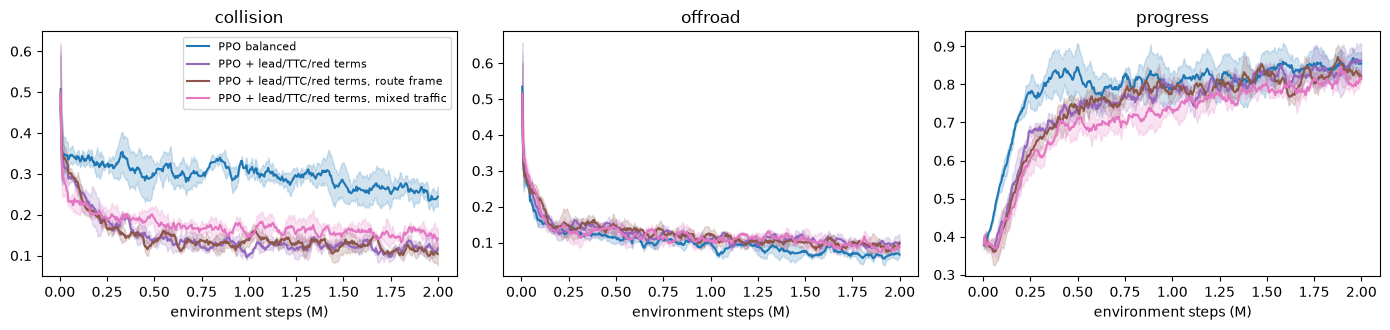

In [25]:
rows = []
for key in ("pure_pursuit", "balanced", "improved", "improved2", "improved3"):
    df = pd.concat(load_method("replay", key))
    counts = df.failure.value_counts(normalize=True)
    t = imp_tables[("replay", "all scenes")].set_index("method").loc[LABELS[key]]
    rows.append({"method": LABELS[key], **{f: round(100 * counts.get(f, 0.0), 1) for f in FAILS},
                 "ran red %": round(100 * df.ran_red.mean(), 1),
                 "mean |jerk|": round(t.mean_abs_jerk, 2), "mean |Δκ|": round(t.mean_abs_dkappa, 4),
                 **offroad_split(df)})
imp_fail = pd.DataFrame(rows)
imp_fail.to_csv(os.path.join(RESULTS_DIR, "improved_failures.csv"), index=False)
display(imp_fail)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for prefix, color in (("balanced", "C0"), ("improved", "C4"), ("improved2", "C5"), ("improved3", "C6")):
    logs = run_logs(prefix)
    n = min(len(lg) for lg in logs)
    x = logs[0].env_steps.values[:n] / 1e6
    for ax, col in zip(axes, ["collision", "offroad", "progress"]):
        ys = np.stack([lg[col].rolling(10, min_periods=1).mean().values[:n] for lg in logs])
        ax.plot(x, ys.mean(0), color=color, label=LABELS[prefix])
        ax.fill_between(x, ys.mean(0) - ys.std(0), ys.mean(0) + ys.std(0), color=color, alpha=0.2)
        ax.set_title(col)
        ax.set_xlabel("environment steps (M)")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "improved_training.png"), dpi=130)
plt.show()

### The same scenes before and after

Three held-out scenes where the balanced policy (seed 0) collides and the policy with the
lead-vehicle terms (seed 0) succeeds, with the hand-designed controller for reference.
Each panel is the last step of the episode.

scenes: [(0, 'waiting', 'collision_other'), (1, 'waiting', 'collision_turning'), (11, 'driving', 'rear_end')]


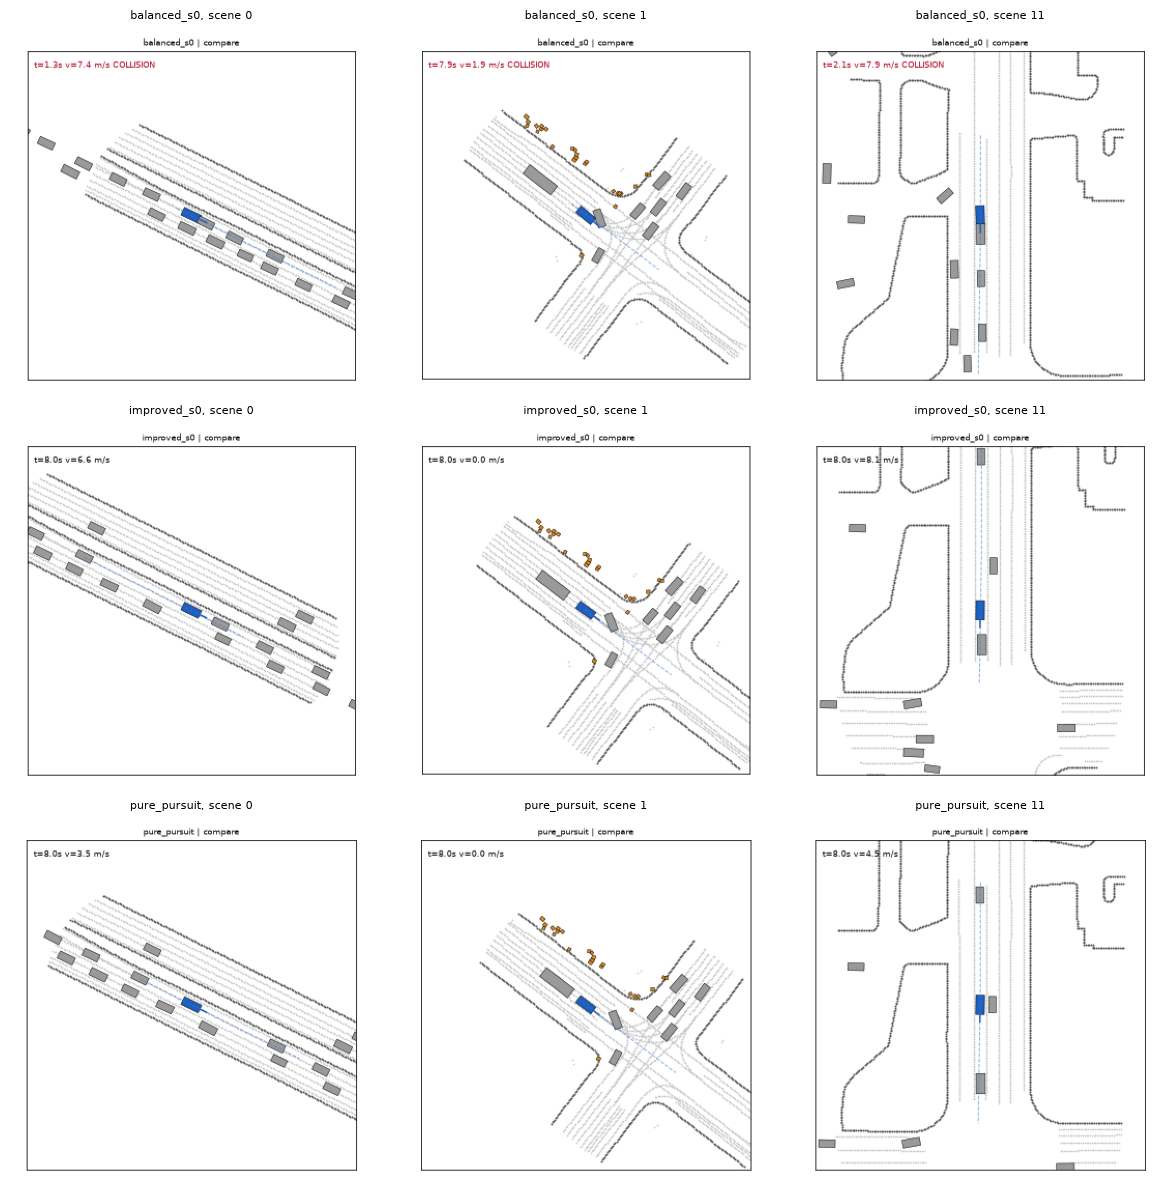

In [26]:
bal = pd.read_csv(os.path.join(RESULTS_DIR, "replay", "balanced_s0.csv"))
imp = pd.read_csv(os.path.join(RESULTS_DIR, "replay", "improved_s0.csv"))
fixed = bal.collision & imp.success
scenes = list(bal.index[fixed & (bal.kind == "waiting")][:2]) + list(bal.index[fixed & (bal.kind == "driving")][:1])
print("scenes:", [(int(i), bal.kind[i], bal.failure[i]) for i in scenes])
if scenes:
    rows = (("ppo", "balanced_s0", None), ("ppo", "improved_s0", IMPROVED["improved"]),
            ("pure_pursuit", None, None))
    fig, axes = plt.subplots(len(rows), len(scenes), figsize=(4 * len(scenes), 4 * len(rows)), squeeze=False)
    for j, i in enumerate(scenes):
        for ax, (method, run, kw) in zip(axes[:, j], rows):
            frames = render_episode(method, run, int(i), "compare", os.path.join(VIDEO_DIR, run or method),
                                    env_kwargs=kw)
            ax.imshow(frames[-1])
            ax.set_title(f"{run or method}, scene {i}", fontsize=8)
            ax.axis("off")
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, "improved_frames.png"), dpi=110)
    plt.show()

## 15. Findings

All numbers below come from the tables and CSV files this notebook writes to `results/`
(`tables.md`, `h1_paired_tests.csv`, `h2_traffic.csv`, `idm_check.csv`,
`h3_reward_study.csv`, `failure_types.csv`, `failure_context.csv`, `smoothness.csv`,
`classifier_check.csv`, `offroad_context.csv`, `stretch_failures.csv`,
`improved_paired_tests.csv`, `improved_failures.csv`). PPO results are the mean over
three training seeds; brackets are 95 % bootstrap confidence intervals over (seed, scene).

**Data.** The two shards hold 766 scenes. Every scene was used: 478 for training and
288 held out for evaluation, of which 168 are *driving* scenes (the human covers at
least 20 m in the 8 s we control) and 120 are *waiting* scenes (queues, red lights,
parked). Keeping the 64 objects closest to the ego's path instead of the first 32 in
file order matters: it leaves on average 0.3 of the ~19 objects that pass within 30 m
of the ego out of the simulation, where the file-order cap left out about five. The
logged human trajectory replayed through our wrapper collides in 0.3 % of held-out
scenes, leaves the road in 1.7 % (label noise in the map or boxes) and crosses an
on-route stop line on red in 1.4 % (this includes legal right turns on red, so it is the
reference level for that metric rather than zero).

**H1 (PPO safer than the hand-designed controller) is not supported.** With the
balanced reward PPO collides in 28.6 ± 1.1 % [24.2, 33.1] of held-out scenes against
7.3 % [4.5, 10.4] for pure pursuit with IDM speed control. On a per-scene basis PPO
collides alone in 68 scenes and the controller alone in 9 (McNemar p < 0.001), and
PPO's success rate is 19.2 points lower (paired 95 % CI [−24.3, −13.5]). Off-road rates
are close (4.2 % vs 3.8 %). Most of the gap comes from the waiting scenes. In driving
scenes PPO reaches 98.3 % of the logged route against 95.6 % for the controller, with
15.7 % collisions against 7.7 % and 80.4 % success against 85.1 %. In waiting scenes it
collides in 46.7 % of episodes and runs a red light in 21.9 %, against 6.7 % and 5.0 %
for the controller: the policy did not learn to stay put when the human did. None of the
four PPO settings beats the controller on collisions.

**H2 (a replay-trained policy gets worse with reactive traffic) does not hold; the
effect goes the other way.** Under IDM traffic the replay-trained balanced policy
collides in 26.3 ± 0.6 % of scenes (28.6 % with replay) and the safety-focused policy in
14.0 ± 1.3 % (21.4 % with replay). Reactive cars brake for an ego that is slower or
closer than the human was, which forgives exactly the mistakes replayed cars punish.
The hand-designed controller is unchanged (7.3 % in both), while the replayed human
trajectory goes from 0.3 % to 6.6 %, because its fixed motion no longer matches cars
that now drive differently. Policies trained with IDM traffic collide in 23.8 ± 0.4 %
under IDM, a little lower than the replay-trained ones, but 33.0 ± 2.3 % with replayed
traffic: training against forgiving traffic does not carry over to the recorded one.
This matches the ablation in the Waymax paper (Gulino et al., 2023), where a DQN agent
trained on replayed traffic also collided less when evaluated with IDM agents. Our
vectorised IDM agrees with Waymax's `IDMRoutePolicy` on the per-scene collision outcome
in 83–87 % of scenes, but Waymax's version produces more collisions for every method
(14.6 % vs 6.6 % for the logged human), partly because its cars keep driving straight after their recorded path ends. For the
one PPO run in that check (balanced, seed 0) collisions are 30.2 % on replay, 27.1 % under
our IDM and 30.9 % under Waymax's, so the reversal holds for our IDM agents and is not
reproduced with Waymax's on that run.

**H3 (higher penalties trade progress for safety, and stop-and-wait if pushed too far)
is supported.** As the collision and off-road weight goes from 10 to 50 to 200,
collisions fall from 54.2 % to 28.6 % to 21.4 % and progress in driving scenes falls from
105.1 % to 98.3 % to 73.1 % of the logged route. Stop-and-wait appears only at the highest
penalty: the safety-focused policy stalls (no failure, under half the logged distance) in
14.5 % of driving scenes, consistently across seeds (17.3 %, 11.9 %, 14.3 %), and neither of the other two reward settings stalls at all. It is also the only setting that copes with waiting scenes
(21.4 % collisions against 46.7 % for balanced), so the same caution that helps when
the human waited costs progress when the human drove. Its overall success rate (53.5 %)
is lower than the balanced policy's (66.6 %) despite the lower collision rate. In the
label check below, six of ten sampled *stalled* episodes were standing still at the end
and four were still moving slowly, so the stalled count mixes stopping with hesitant
driving.

**Failure analysis.** For the balanced policy the most common failure is running into
the vehicle ahead (13.2 % of episodes), often creeping into a stopped queue, followed by
other collisions (9.1 %), collisions while turning (4.7 %) and leaving a straight road
(4.2 %). Its median speed at the moment of failure is 5.2 m/s, and 5.7 % of its
collisions involve a pedestrian or cyclist. The progress-focused policy fails in 94 % of
waiting scenes. The hand-designed controller's collisions are few; the largest labelled groups are
other collisions (3.1 %) and a replayed car running into it from behind (2.8 %). The
second is an artifact of log replay when the ego is slower than the human, not a mistake
by the controller. The safety-focused policy is
struck from behind more often (6.6 %) for the same reason, and stalls in 8.4 % of all
episodes. The rendered episodes in `videos/` and `figures/failure_frames.png` show these
cases.

**How far to trust the failure types.** We checked 70 sampled episodes by eye (ten per
type) and agreed with the label in 44. *Struck from behind* (10/10), *off-road on a
straight* (9/10) and *rear-end* (8/10) hold up. *Collision while turning* does not
(3/10): seven of the ten were the ego going straight into a vehicle ahead or a crossing
vehicle, labelled as turning because the policy's own steering corrections push its
curvature over the threshold. Three of ten *other collisions* were rear-ends too. The
rear-end share reported for PPO is therefore an undercount, which strengthens the
diagnosis rather than weakening it. *Off-road on a curve* (1/10) is mostly something
else: the progress-focused policy driving past the end of the logged path. The route
beyond that point is a straight 30 m extension that need not stay on the road. Splitting
off-road events by where they happen (`offroad_context.csv`) shows that 1.4 % of scenes
start with the ego outside the mapped road for every method, the logged human included,
and that within the logged path the rates are low and close together: 1.0 % for the
controller, 1.3 % balanced, 1.9 % progress-focused, 2.2 % safety-focused. The
progress-focused policy's 11.7 % is mostly overrun (8.4 %). We kept the classifier as it
was and report these error rates with it; the hypothesis tests do not use the types.

**Smoothness.** PPO drives less smoothly than every reference: mean absolute jerk of
3.6 m/s³ for the balanced policy against 1.8 for the controller and 1.3 for the human,
and curvature changes of 0.0073 1/m per step against 0.0003, about 23 times larger,
which shows up in the videos as constant small steering corrections.

**Stretch goals.** Behaviour cloning on 38,240 inverse-dynamics expert actions fits the
data well (mean squared error 0.003) but fails in closed loop: 38.5 % collisions, 42.7 %
off-road and 14.9 % success, the compounding-error problem of open-loop imitation.
Starting PPO from the cloned policy ends at 28.4 ± 2.6 % collisions and 64.8 ± 3.5 %
success over three seeds, the same as PPO from scratch (28.6 % and 66.6 %), so with this
budget the warm start neither helps nor hurts. A richer observation with the 10 nearest
objects and 16 road-edge points is worse on every seed: 34.5 ± 2.6 % collisions and
56.2 ± 2.8 % success. More inputs make the problem harder to learn in 2M steps rather than
easier. For the harder slice we trained three seeds only on the 100 training scenes
where the ego turns or crosses a signal's stop line, and evaluated on the 45 held-out
scenes of the same kind. There the specialised policy collides less than the policy
trained on all scenes (13.3 ± 3.1 % vs 18.5 ± 2.8 %, hand-designed 8.9 %) but leaves the
road more (11.9 % vs 3.7 %), and its success rate is no better (72.6 % vs 76.3 %,
hand-designed 75.6 %). Over all 288 scenes it is worse (33.4 % collisions, 55.6 %
success), because it rarely saw a queue or a straight road. The data matter more than
the specialisation: a fifth of the training set is not enough to learn the slice well.
None of the stretch policies shows stop-and-wait (stalled in 0 to 1 % of driving scenes;
2.4 % for behaviour cloning), and under reactive IDM traffic their ranking by success rate is the same, with collision
rates of
27.7 ± 1.9 % collisions for BC → PPO, 28.7 ± 4.0 % for the richer observation and
32.1 ± 0.7 % for the intersection-trained policy, against 26.3 % for balanced.

**Improving the policy (section 14).** The failure analysis pointed at a missing input,
so we gave the policy the gap, closing speed and time to collision to whatever is ahead
in its lane (a vehicle or a red stop line), penalised time to collision below 2 s and
red-light violations, and doubled the control weight. Nothing else changed. Over three
seeds on replayed traffic this cuts collisions from 28.6 % to 9.5 ± 2.7 % [6.8, 12.4]
and raises success from 66.6 % to 81.8 ± 2.8 % [78.1, 85.4] (paired: 66 scenes where only
the balanced policy collides vs 7, success +15.3 points [10.3, 20.3]). The gain is where
the analysis said it would be. In waiting scenes collisions fall from 46.7 % to 10.8 % and
red-light violations from 21.9 % to 4.7 %. Rear-end collisions fall from 13.2 % to 1.4 % of
episodes. Jerk falls from 3.6 to 2.3 m/s³. Against the hand-designed controller the
collision difference is gone: each collides alone in 13 scenes (McNemar p = 1.0). The
success rate is 3.9 points lower [−8.2, 0.2], mostly because the improved policy leaves
the road more often (7.8 % vs 3.8 %). Most of that difference is overrun: the improved
policy drives further than the human did, and 4.7 % of its episodes leave the road after
the end of the logged path, against 1.4 % for the controller; within the logged path the
rates are 1.6 % and 1.0 %. We first suspected that steering out of the lane was a
way to hide the stopped car from a feature measured along the ego's heading, so a second
version measures it along the route. That lowers off-road exits (6.5 %, and 6.1 % vs
9.2 % in waiting scenes; overrun falls from 4.7 % to 2.7 %) but raises collisions slightly (11.1 %), and the two versions are
not significantly different (13 vs 7 scenes, p = 0.26). Two caveats. Curvature changes are still about 12 times the controller's. More importantly, the gain does not carry
over to reactive traffic: under IDM the improved policies collide in 21.8 % and 19.7 % of
scenes, only modestly below the balanced policy (26.3 %, p = 0.004) and far above the
controller (7.3 %), with most of the extra collisions in waiting scenes.
We have not isolated why. One candidate is that our IDM agents restart stopped cars
toward their maximum logged speed and stop steering them once their logged path ends, a pattern
the policy never saw in training.

**Mixed-traffic training.** A third version tests that explanation by training the first
one on a mix of replayed and reactive episodes. Under IDM traffic collisions fall from
21.8 % to 17.0 ± 0.5 % and success rises from 68.4 % to 71.8 ± 0.7 % (paired against the
first version: 18 scenes where only the replay-trained policy collides vs 5, p = 0.011;
success +3.4 points [0.3, 6.6]), with most of the gain in waiting scenes (31.4 % to 23.3 %
collisions). On replayed traffic it gives a little back: 11.3 ± 2.6 % collisions and
78.6 ± 1.5 % success against 9.5 % and 81.8 % (12 vs 4 scenes, p = 0.08; success −3.2
points [−5.9, −0.5]). Seeing reactive cars in training buys robustness at a small cost on
recorded traffic, the same direction as the H2 result. It narrows the gap without closing it: under
IDM the controller still collides in 7.3 % of scenes (34 vs 11, p < 0.001).

**Limitations.** One shard per split; 2M environment steps per run on a CPU; red-light
attribution is a geometric heuristic; the failure types are right in about two thirds of
the episodes we checked; off-road events after the end of the logged path depend on a
straight route extension; the hand-designed controller takes its desired speed from the
logged trajectory; the reactive
IDM agents follow their logged paths, so they never change lanes or yield at crossings;
the IDM ego baseline uses state dynamics and is not bound by the bicycle model; the
policy sees only the five nearest objects and the next signal, which leaves the problem
partially observable; and the section 14 changes were designed after looking at the
held-out failure analysis (and the mixed-traffic version after the reactive-traffic
result), so their numbers are repeated looks at the same scenes rather than a fresh test.

**Summary.** In real WOMD traffic a compact PPO policy learns to drive along its route
about as far as the human did, but with the observation and reward from the proposal it
is clearly less safe than a simple pure-pursuit controller with IDM speed control,
mostly because it does not learn when to wait. Larger penalties reduce collisions at the
cost of progress and eventually produce the stop-and-wait behaviour the proposal
anticipated. Switching to reactive traffic makes replay-trained policies look safer, not
worse, which says as much about how forgiving the traffic model is as about the policy.
Giving the policy an explicit lead-vehicle signal and a time-to-collision term closes
the collision gap to the controller on replayed traffic (9.5 % vs 7.3 %, not
significantly different), but not under reactive traffic. Training on mixed traffic
narrows that gap (21.8 % to 17.0 % collisions) without closing it, so the remaining
difference between learned and hand-designed driving here is robustness rather than
average-case safety.